# Retail Customer Segmentation and Marketing Strategy

## Executive summary

**Recommendation:** use four K-Means customer segments as a working framework for differentiated marketing pilots, with K=3 retained as a simpler comparison. Four profiles make grocery-oriented family purchasing and higher-income omnichannel activity separately visible, although K=3 has stronger internal clustering metrics. Whether that extra distinction improves business outcomes remains a question for testing.

The analysis covers **2,000 customers** and eight clustering features, with five principal components retaining **81.57%** of variance. The largest segment, fashion and technology shoppers, contains **744 customers (37.2%)**, with median online spending of **SGD 900/month** and **13 online visits/month**. This gives a clear starting hypothesis for an on-platform recommendation pilot. Family-focused shoppers have the highest median grocery spending; high-income omnichannel shoppers have higher spending across several categories and activity in both channels; low-engagement shoppers provide a separate repeat-purchase test group.

**Project scope:** an individual academic customer-analytics project with a simulated business brief. The business context describes a decision scenario, while the numerical evidence comes from executed analysis of course-provided data. The deliverables are a reproducible Python reporting workflow, verified customer profiles, model-selection evidence and a proposed KPI/experimental measurement specification. No retailer engagement, deployed system or measured campaign uplift is claimed.

## Business context and decision brief

**Simulated business setting.** An omnichannel retailer wants to plan differentiated category offers, customer engagement and membership benefits. Its customer file combines purchasing patterns, income and visits across physical and online channels. The simulated brief asks an analyst to move beyond a single broad marketing audience and give the marketing manager a practical way to define test groups.

The scenario represents a business decision problem; it does not document an actual retailer's campaign performance, budgets or operating practices. All numerical findings below come from the course-provided customer data.

| Decision gap in the simulated brief | Business question | Analytical response |
| --- | --- | --- |
| A broad audience offers little guidance on which products to emphasize | Which category-spending patterns warrant different offers? | Group customers using spending, channel visits and purchasing capacity; describe each group in original units |
| The appropriate engagement channel is unclear | Which groups show stronger online activity or activity in both channels? | Compare monthly online/store visits and online spending by segment |
| More segments add planning complexity | Does a fourth group support a meaningful additional decision? | Compare K=3 and K=4 using internal metrics, stability, memberships and business profiles |

The primary objective is to recommend an interpretable working segmentation and translate it into testable marketing hypotheses. The intended stakeholder is a marketing or customer-insights manager deciding which audiences, offers and channels to pilot. Success at this analytical stage means transparent profiles, justified model choices and a reproducible workflow. Commercial success would need purchase, exposure and cost data from a later controlled test.

## Data overview and source

The MAV552 January 2026 assignment at Singapore University of Social Sciences provides the course dataset and scenario. One row represents a customer; spending is approximate average monthly SGD, income is monthly SGD, and visits are monthly channel averages. The assignment's consulting scenario is an academic framing. The source CSV is included; the original report and assignment paper are retained separately. See [data definitions and availability](../data/README.md).



## Execution setup
Use a fresh Python kernel with the pinned requirements. The included `data/raw/customer_segmentation.csv` is used by default. Set `SEGMENTATION_DATA` to use another CSV location. Only aggregate outputs are exported. Thread configuration precedes numerical imports.

In [1]:
import os
os.environ.setdefault('OMP_NUM_THREADS', '1')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '1')
os.environ.setdefault('MKL_NUM_THREADS', '1')
from pathlib import Path
import sys
root = Path.cwd()
if root.name == 'notebooks':
    root = root.parent
if not (root / 'src' / 'run_analysis.py').is_file():
    raise RuntimeError('Start this Notebook from the repository root or notebooks directory.')
sys.path.insert(0, str(root))
data_path = Path(os.environ.get('SEGMENTATION_DATA', root / 'data' / 'raw' / 'customer_segmentation.csv'))
from IPython.display import display, Image
from src.data import load_data, validate_data
from src.preprocessing import prepare_data, distribution_summary
from src.config import FEATURES
from src.run_analysis import run_analysis
def show_figure(name):
    display(Image(filename=str(root / 'reports' / 'figures' / f'{name}.png'), width=900))

## Data checks
Required schema, numeric types, missingness, identities, categories, finite values and plausibility flags are checked without dropping or altering customers. Source accuracy and missingness mechanisms remain unverified.

In [2]:
raw = load_data(data_path)
audit = validate_data(raw)
for name in ['data_checks', 'data_quality', 'observed_ranges', 'category_overview']:
    print(name.replace('_', ' ').title())
    display(audit[name])

Data Checks


,check,count
0,customer_count,2000
1,column_count,15
2,duplicate_rows,0
3,duplicate_ids,0
4,missing_cells,200
5,fields_with_missing_values,4
6,negative_observed_values,0
7,age_outside_18_to_100,0
8,income_above_100000_SGD,1
9,store_visits_above_60_per_month,15


Data Quality


,field,dtype,missing_count,missing_share
0,customer_id,str,0,0.000
1,gender,str,0,0.000
2,age,int64,0,0.000
3,marital_status,str,0,0.000
4,education_level,str,0,0.000
5,monthly_income,float64,50,0.025
6,num_children,float64,50,0.025
7,spend_grocery,int64,0,0.000
8,spend_fashion,int64,0,0.000
9,spend_electronics,float64,50,0.025


Observed Ranges


,field,min,max,median
0,age,20.0,65.0,36.0
1,monthly_income,1500.0,999999.0,6650.0
2,num_children,0.0,5.0,0.0
3,spend_grocery,100.0,1750.0,650.0
4,spend_fashion,0.0,1500.0,450.0
5,spend_electronics,0.0,1650.0,500.0
6,spend_dining,0.0,1700.0,600.0
7,spend_online,0.0,1850.0,600.0
8,visits_store_per_month,0.0,100.0,4.0
9,visits_online_per_month,0.0,29.0,8.0


Category Overview


,category,count,field,share
0,Female,1038,gender,0.5190
1,Male,962,gender,0.4810
2,Married,1136,marital_status,0.5680
3,Single,663,marital_status,0.3315
4,Divorced,201,marital_status,0.1005
5,Bachelor,1002,education_level,0.5010
6,Master,581,education_level,0.2905
7,High School,287,education_level,0.1435
8,PhD,130,education_level,0.0650


## Data preparation and analytical design

The dataset contains 2,000 customers and 15 fields. There are 200 missing cells: 50 each in income, children, electronics spending and online spending (2.5% per field). Checks found no duplicate rows or customer IDs, unsupported category values, negative observed numeric values, or nonfinite observed numeric values. Age and loyalty are checked against explicit plausibility ranges; these checks do not certify source accuracy. Income reaches SGD 999,999 per month and store visits reach 100 per month. These are unverified extremes or possible placeholders, retained without capping or deletion. The exported audit includes counts, ranges and category frequencies.

Income and children use median imputation; electronics and online spending use mean imputation. Imputed children are cast to integers. This assumes the observed central values are reasonable substitutes, without evidence that missingness is random. A separate imputed frame retains original units for profiling. The model frame applies `log1p` to income and store visits, then StandardScaler to the eight features in a fixed order. Logs compress differences at high values; scaling makes distance reflect standardized feature differences. Neither guarantees removal of outlier influence. Distribution and IQR summaries show their effects without removing observations.

Clustering uses income, five spending fields, and two channel-visit fields. Income represents purchasing capacity. The identifier and demographics are excluded to focus segmentation on purchasing patterns; demographics are summarized afterward. Loyalty is excluded because it is constructed from spending and visits, reducing redundancy. Pairwise correlations alone cannot establish absence of multicollinearity. Online spending is analyzed separately because overlap with category spending is undocumented.

PCA is fit to all eight transformed standardized features (`random_state=64`, no whitening, `svd_solver='auto'`). Five score columns retain 81.57% of variance. This is a compression tradeoff, not a guarantee of retained business value. The exported weights are `components_.T`, not component weights multiplied by explained standard deviation. Signs are arbitrary and do not change distances. No clustering in alternate representations is evaluated here.

PC1 combines fashion (0.435), dining (0.414), online spending (0.416), online visits (0.410) and other purchasing-capacity features. PC2 contrasts grocery (0.572) and store visits (0.553) with online visits (-0.324). PC3 emphasizes electronics (0.744) against fashion (-0.404) and store visits (-0.357). These are feature combinations, not customer segments.

In [3]:
profile, transformed, scaled, scaler, imputation = prepare_data(raw)
display(imputation)
print('Feature order:', FEATURES)
print('Before log1p')
display(distribution_summary(profile))
print('After log1p')
display(distribution_summary(transformed))
display(transformed.corr().round(3))

,field,imputation,fill_value
0,monthly_income,median,6650.000000
1,num_children,median,0.000000
2,spend_online,mean,626.257179
3,spend_electronics,mean,518.820513


Feature order: ['monthly_income', 'spend_grocery', 'spend_fashion', 'spend_electronics', 'spend_dining', 'spend_online', 'visits_store_per_month', 'visits_online_per_month']
Before log1p


,skewness,outside_IQR_share
monthly_income,36.298951,0.0870
spend_grocery,0.529729,0.0160
spend_fashion,0.582896,0.0120
spend_electronics,0.400582,0.0095
spend_dining,0.348032,0.0050
spend_online,0.402771,0.0035
visits_store_per_month,10.073844,0.0075
visits_online_per_month,0.524030,0.0005


After log1p


,skewness,outside_IQR_share
monthly_income,1.042507,0.0095
spend_grocery,0.529729,0.0160
spend_fashion,0.582896,0.0120
spend_electronics,0.400582,0.0095
spend_dining,0.348032,0.0050
spend_online,0.402771,0.0035
visits_store_per_month,0.425746,0.0075
visits_online_per_month,0.524030,0.0005


,monthly_income,spend_grocery,spend_fashion,spend_electronics,spend_dining,spend_online,visits_store_per_month,visits_online_per_month
monthly_income,1.000,0.267,0.275,0.374,0.450,0.212,0.335,0.209
spend_grocery,0.267,1.000,-0.150,0.043,0.105,-0.245,0.400,-0.318
spend_fashion,0.275,-0.150,1.000,0.304,0.379,0.444,0.047,0.424
spend_electronics,0.374,0.043,0.304,1.000,0.335,0.291,0.117,0.310
spend_dining,0.450,0.105,0.379,0.335,1.000,0.289,0.272,0.276
spend_online,0.212,-0.245,0.444,0.291,0.289,1.000,-0.092,0.503
visits_store_per_month,0.335,0.400,0.047,0.117,0.272,-0.092,1.000,-0.207
visits_online_per_month,0.209,-0.318,0.424,0.310,0.276,0.503,-0.207,1.000


## Reusable complete workflow
The shared functions calculate PCA, all K-Means and Ward candidates, both K-Means stability procedures, Ward stability, K=3 and K=4 profiles, and direct membership comparisons. The same entry point powers the command-line run and exports all figures and aggregate tables.

## Reproducible reporting and data-quality controls

The Python workflow converts the customer snapshot into a consistent set of segment profiles, diagnostic tables and English figures. A single command regenerates these outputs; the Notebook uses the same functions. This reduces dependence on separately edited spreadsheets or manually maintained chart values. Reporting is triggered by running the analysis, with no scheduled refresh or production service implemented.

| Reporting concern | Implemented control | Evidence available for review |
| --- | --- | --- |
| Input records may be incomplete or inconsistent | Required fields, numeric types, missingness, duplicate IDs/rows, finite values and category checks; explicit plausibility flags | Data-quality, data-check and observed-range tables |
| Transformations may obscure units or customer identity | Separate imputed original-unit profile frame; fixed model-feature order; checks for unchanged observed values and preserved customer order | Preprocessing functions and integrity checks |
| Segment reports may disagree on counts or definitions | Shares calculated from verified counts; medians and means exported separately; categorical counts and within-segment denominators provided | Segment overview, profile and proportion tables |
| A model change may produce misleading comparisons | Candidate/final partition checks, label-invariant ARI/NMI comparisons and customer-membership contingency tables | Partition-agreement and contingency tables |
| Outputs may be difficult to reproduce or hand over | Modular functions, explicit seeds/model settings, pinned packages, one command and focused tests | Source modules, complete Notebook and root execution instructions |

The analysis uses one supplied CSV with 2,000 customer records. It demonstrates local data preparation and reporting controls; warehouse modeling, SQL transformations, multi-source ingestion and large-scale processing are outside the implemented workflow.

For a marketing stakeholder, the [segment overview](../reports/tables/segment_overview.csv) answers who the groups are, the recommendations explain what to test, and the measurement specification below defines what evidence would support a rollout. For a technical reviewer, source functions and comparison tables expose how the profiles were produced. These artifacts are designed for handoff; no real cross-functional team collaboration is claimed by this individual project.

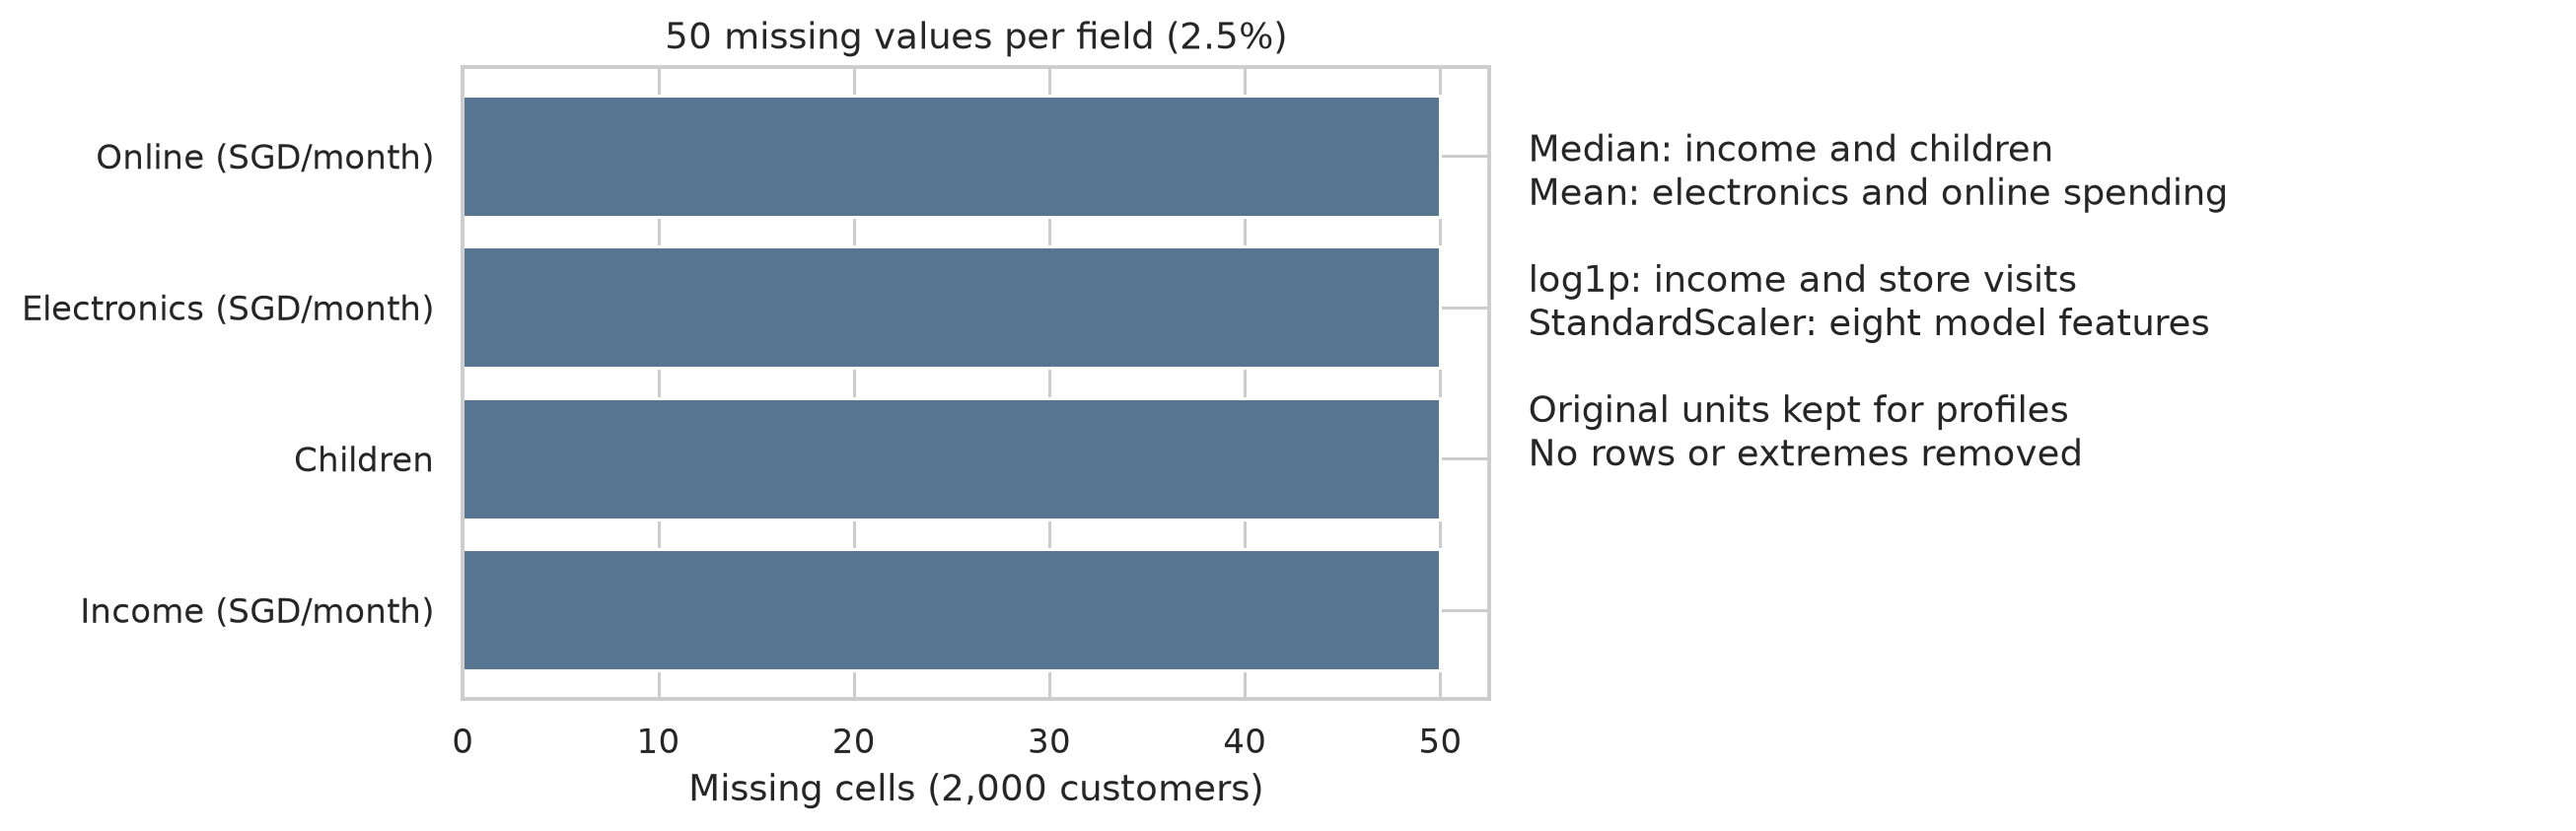

,PC,explained_variance,cumulative_variance
0,PC1,0.340179,0.340179
1,PC2,0.239655,0.579835
2,PC3,0.091374,0.671209
3,PC4,0.074174,0.745383
4,PC5,0.070362,0.815745
5,PC6,0.066643,0.882389
6,PC7,0.062538,0.944926
7,PC8,0.055074,1.000000


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8
monthly_income,0.370892,0.358059,0.147853,-0.440263,-0.000257,-0.098055,0.571224,-0.427351
spend_grocery,-0.059213,0.572021,0.163802,-0.340810,-0.428476,0.374888,-0.348162,0.284525
spend_fashion,0.434612,-0.102479,-0.403888,0.329313,-0.254673,0.647941,0.198155,-0.071316
spend_electronics,0.386794,0.102218,0.744092,0.514735,0.060756,0.019057,-0.128452,-0.027618
spend_dining,0.414096,0.223880,-0.282709,-0.150469,0.660714,0.059130,-0.482497,-0.054727
spend_online,0.415773,-0.250388,-0.125426,-0.119077,-0.546559,-0.446815,-0.425240,-0.235218
visits_store_per_month,0.090689,0.553110,-0.356708,0.429890,-0.095388,-0.471568,0.183629,0.329552
visits_online_per_month,0.409717,-0.323865,0.107765,-0.308209,0.059076,-0.064323,0.222192,0.750760


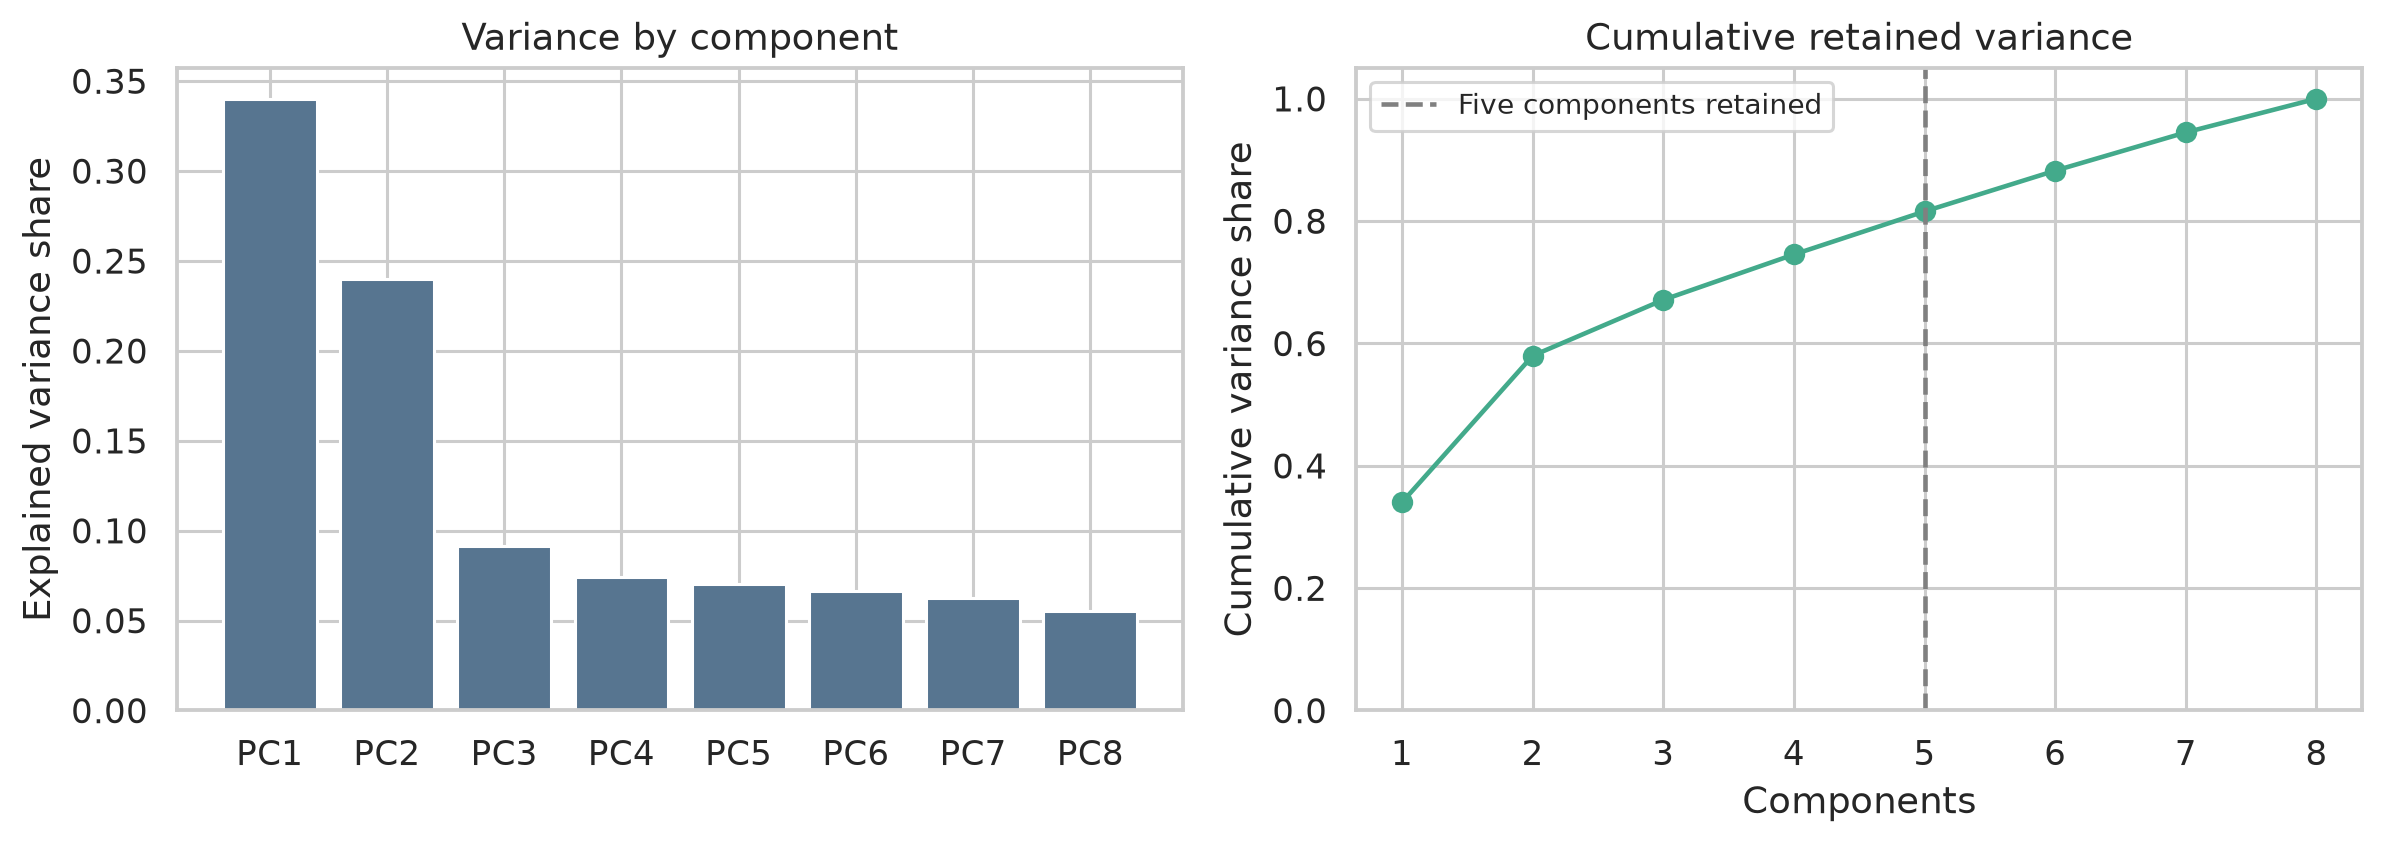

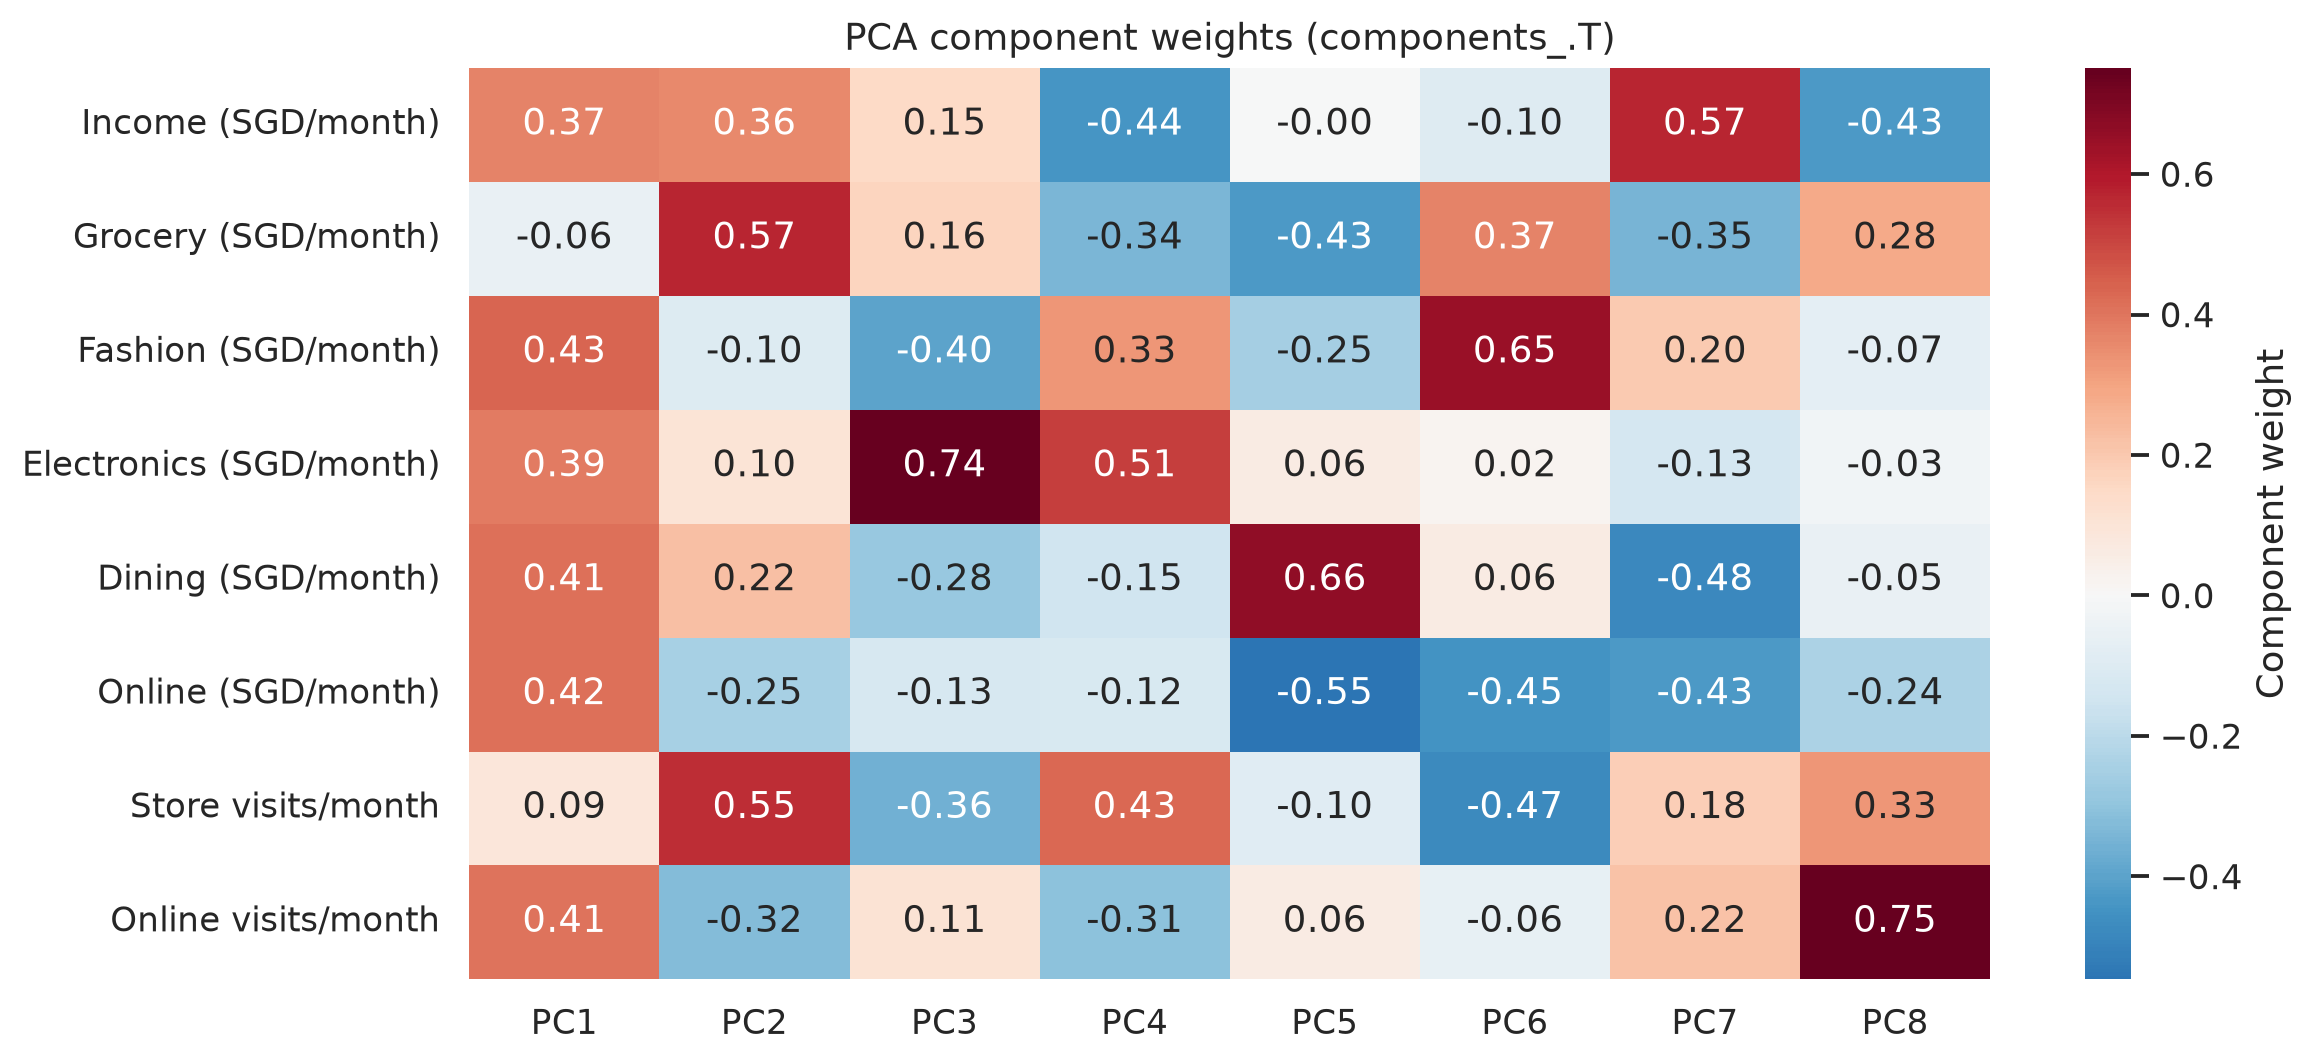

In [4]:
result = run_analysis(data_path, root / 'reports')
tables = result['tables']
show_figure('data_quality')
display(tables['pca_variance'])
display(tables['pca_weights'])
show_figure('pca_variance')
show_figure('pca_weights')

## K-Means evaluation


K-Means candidates cover K=2 through K=10 using k-means++ initialization, `n_init=20`, `random_state=64`, 300 maximum iterations, tolerance 0.0001 and Lloyd's algorithm. Final K=4 and the K=3 comparison use `n_init=30` with the same other settings. In this execution, the candidate and final partitions are identical at K=3 and K=4 (ARI=NMI=1). Inertia, CH and DB use the complete five-PC representation. Silhouette uses a seed-64 sample of 1,000 customers.

| K   | Silhouette   | Calinski-Harabasz   | Davies-Bouldin   | Minimum share   |
|:----|:-------------|:--------------------|:-----------------|:----------------|
| 3   | 0.336        | 1,011.484           | 1.164            | 0.217           |
| 4   | 0.326        | 923.144             | 1.222            | 0.165           |

Higher silhouette and CH, and lower DB, favor K=3. K=4 is an interpretability choice: it distinguishes a grocery-oriented family group from higher-income customers with greater dining, fashion and electronics spending. K=3's broader higher-capacity group has median income SGD 9,500, grocery spending SGD 900, and dining spending SGD 700. K=4 makes those two patterns separately visible in the original-unit profiles below. The K=3/K=4 contingency table documents the actual membership relationship; the solutions need not form a perfectly nested split. Balanced size alone does not establish better segments. There is no campaign-outcome evidence that four groups outperform three.



K-Means subsampling stability fits 12 independent 80% subsets without replacement, seeds 1000 through 1011 and `n_init=20`. Each later fit is compared to the first on correctly aligned shared row indices (11 comparisons). K=4 mean ARI is 0.974 (SD 0.012); mean NMI is 0.961 (SD 0.017). Initialization stability fits all customers 12 times with seeds 2000 through 2011 and `n_init=1`, comparing later runs to the first (11 comparisons). Its K=4 mean ARI/NMI is 0.986/0.976. Standard deviations use population `ddof=0`. These statistics measure agreement, not ground-truth accuracy. Subset runs retain the full-data scaler and PCA; stability therefore does not measure re-estimation of the entire preprocessing pipeline.

,K,inertia,silhouette,CHI,DBI,minClusterRatio
0,2,9044.844510,0.280923,885.160833,1.401885,0.4285
1,3,6483.806677,0.335572,1011.483549,1.164411,0.2170
2,4,5466.795004,0.325624,923.143862,1.222175,0.1650
3,5,4862.328123,0.291559,840.042087,1.387020,0.1605
4,6,4580.452639,0.274024,737.579557,1.486670,0.0830
5,7,4332.103695,0.265237,668.597383,1.517221,0.0895
6,8,4131.617882,0.242564,614.407965,1.620660,0.0710
7,9,3957.506982,0.236050,571.918813,1.591753,0.0740
8,10,3833.203663,0.230211,531.764387,1.633140,0.0630


,K,n_init,inertia,silhouette,CHI,DBI,minClusterRatio
0,3,30,6483.806677,0.335572,1011.483549,1.164411,0.217
1,4,30,5466.795004,0.325624,923.143862,1.222175,0.165


,K,ARI_mean,ARI_std,NMI_mean,NMI_std,ARI_init_mean,ARI_init_std,NMI_init_mean,NMI_init_std
0,2,0.986118,0.012552,0.971002,0.023315,0.814510,0.378696,0.808399,0.378856
1,3,0.987896,0.004865,0.975783,0.008424,0.997198,0.001321,0.994649,0.002522
2,4,0.973932,0.011838,0.960618,0.016505,0.985618,0.007446,0.976315,0.011403
3,5,0.970584,0.006405,0.961484,0.007029,0.793595,0.121797,0.819206,0.074914
4,6,0.902588,0.081183,0.902162,0.063820,0.810626,0.115451,0.825135,0.076525
5,7,0.809458,0.095835,0.811881,0.079794,0.735348,0.119294,0.783315,0.080541
6,8,0.780537,0.080377,0.805291,0.060575,0.727594,0.107330,0.770263,0.067902
7,9,0.781783,0.041405,0.806604,0.028053,0.695621,0.085101,0.749390,0.041801
8,10,0.709971,0.068533,0.757618,0.053638,0.696325,0.090006,0.746813,0.042656


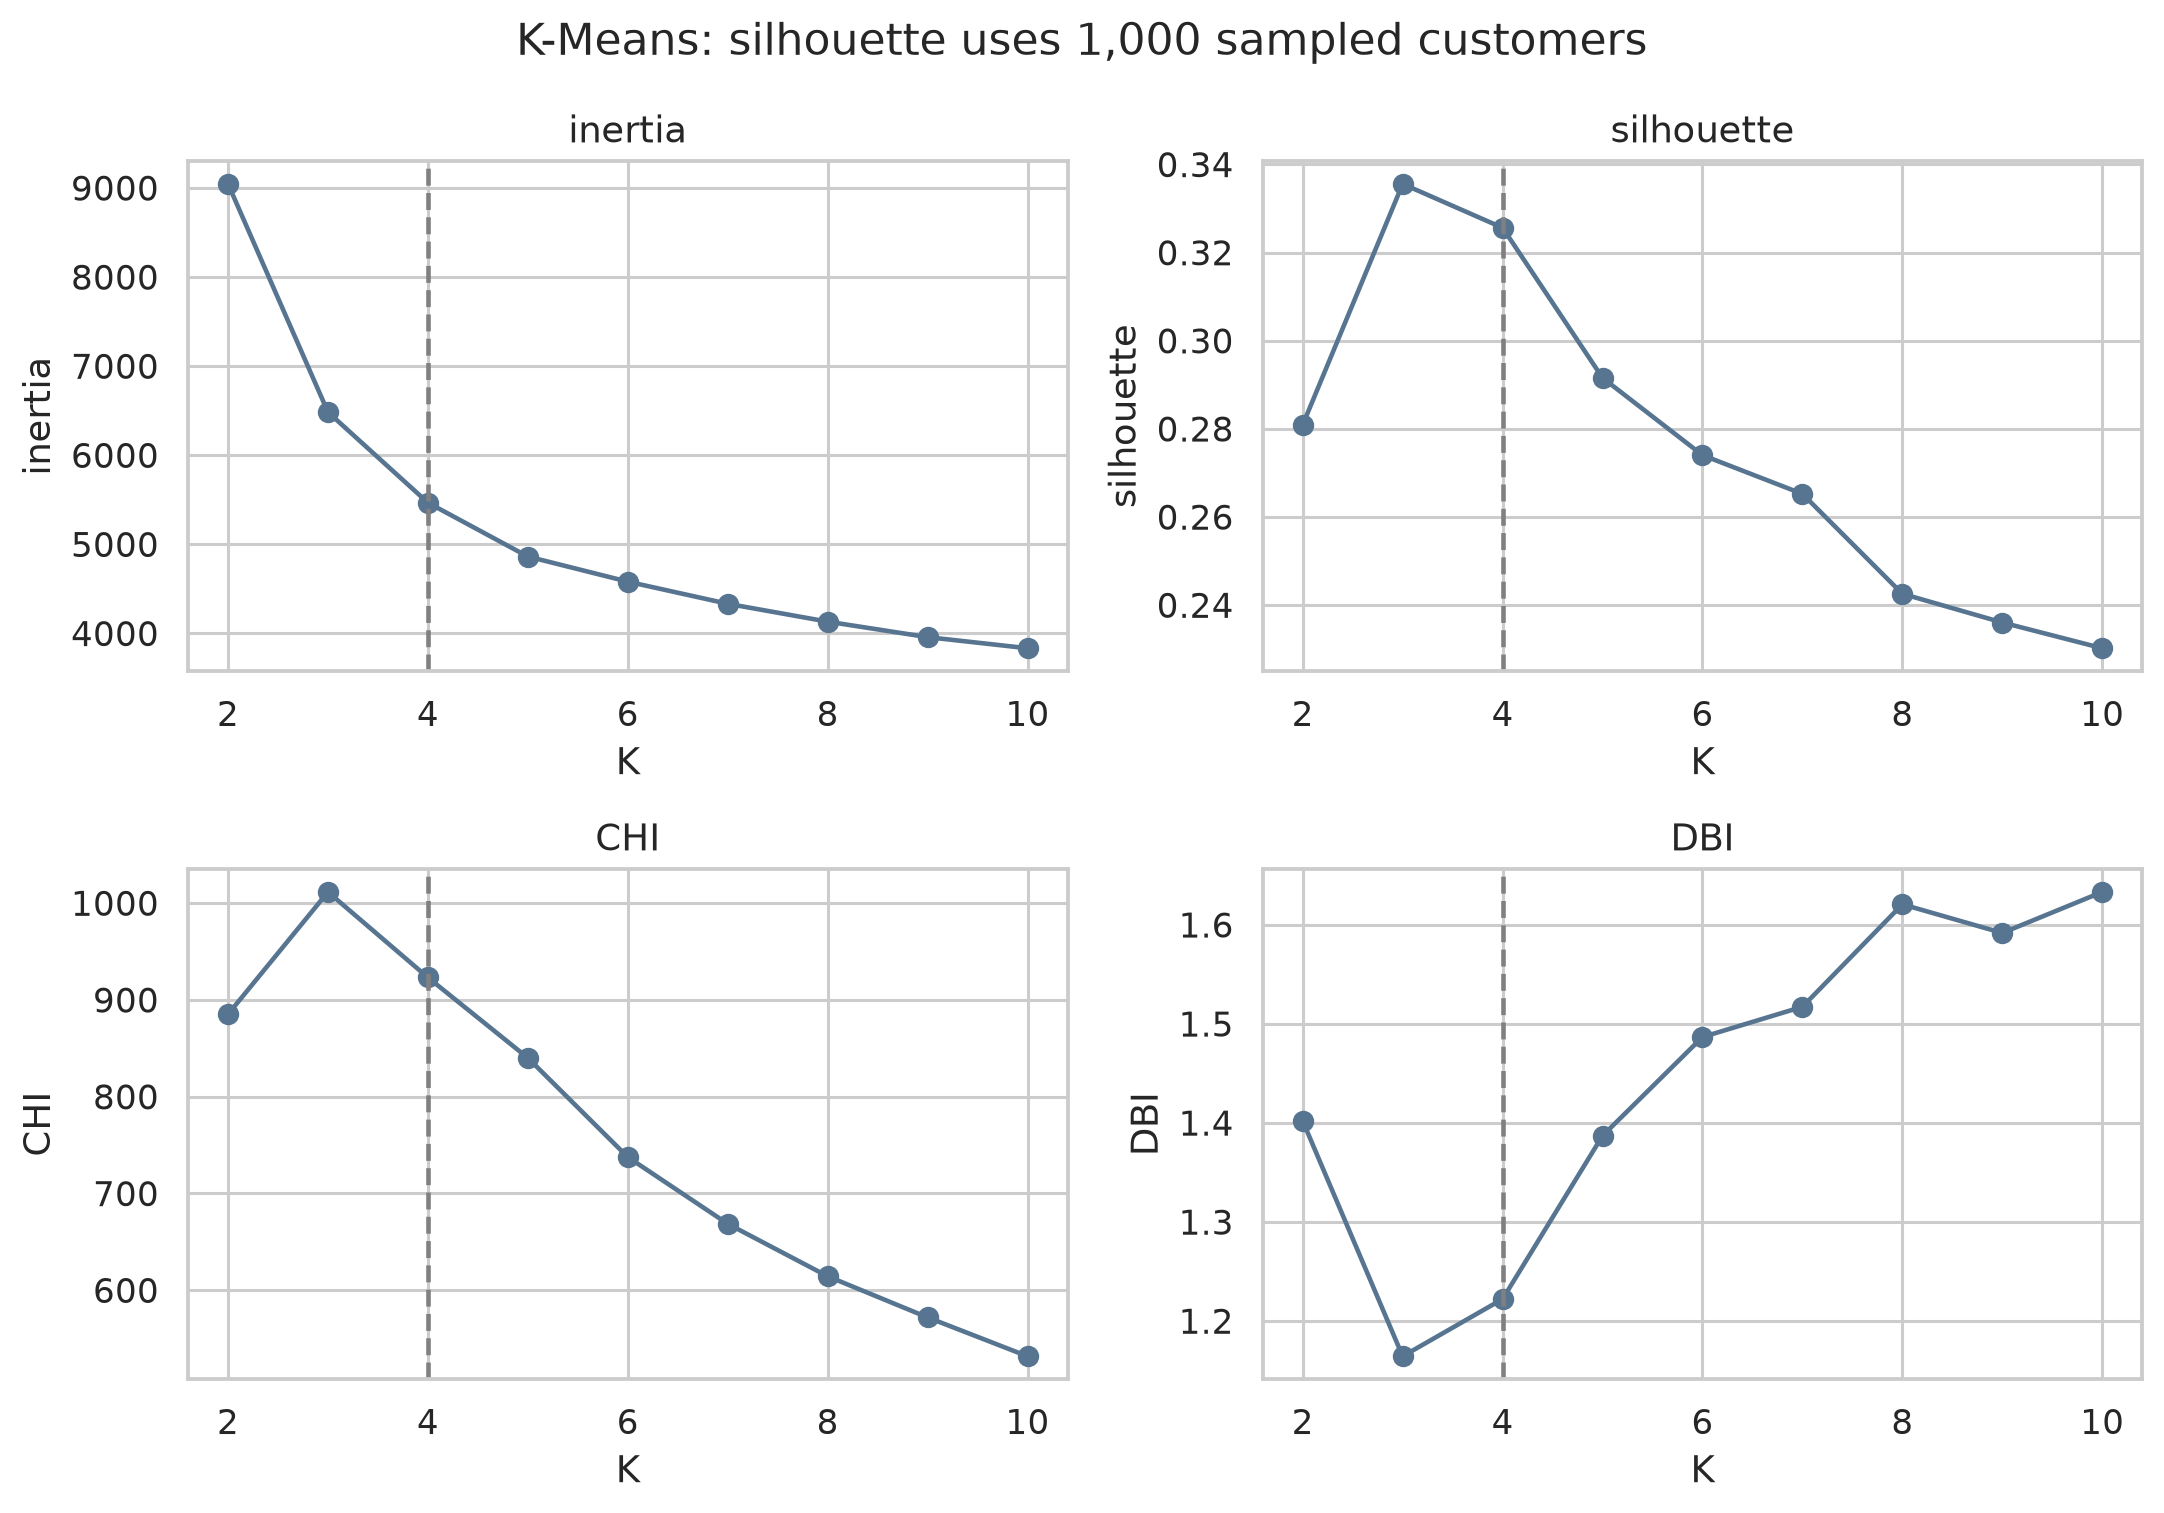

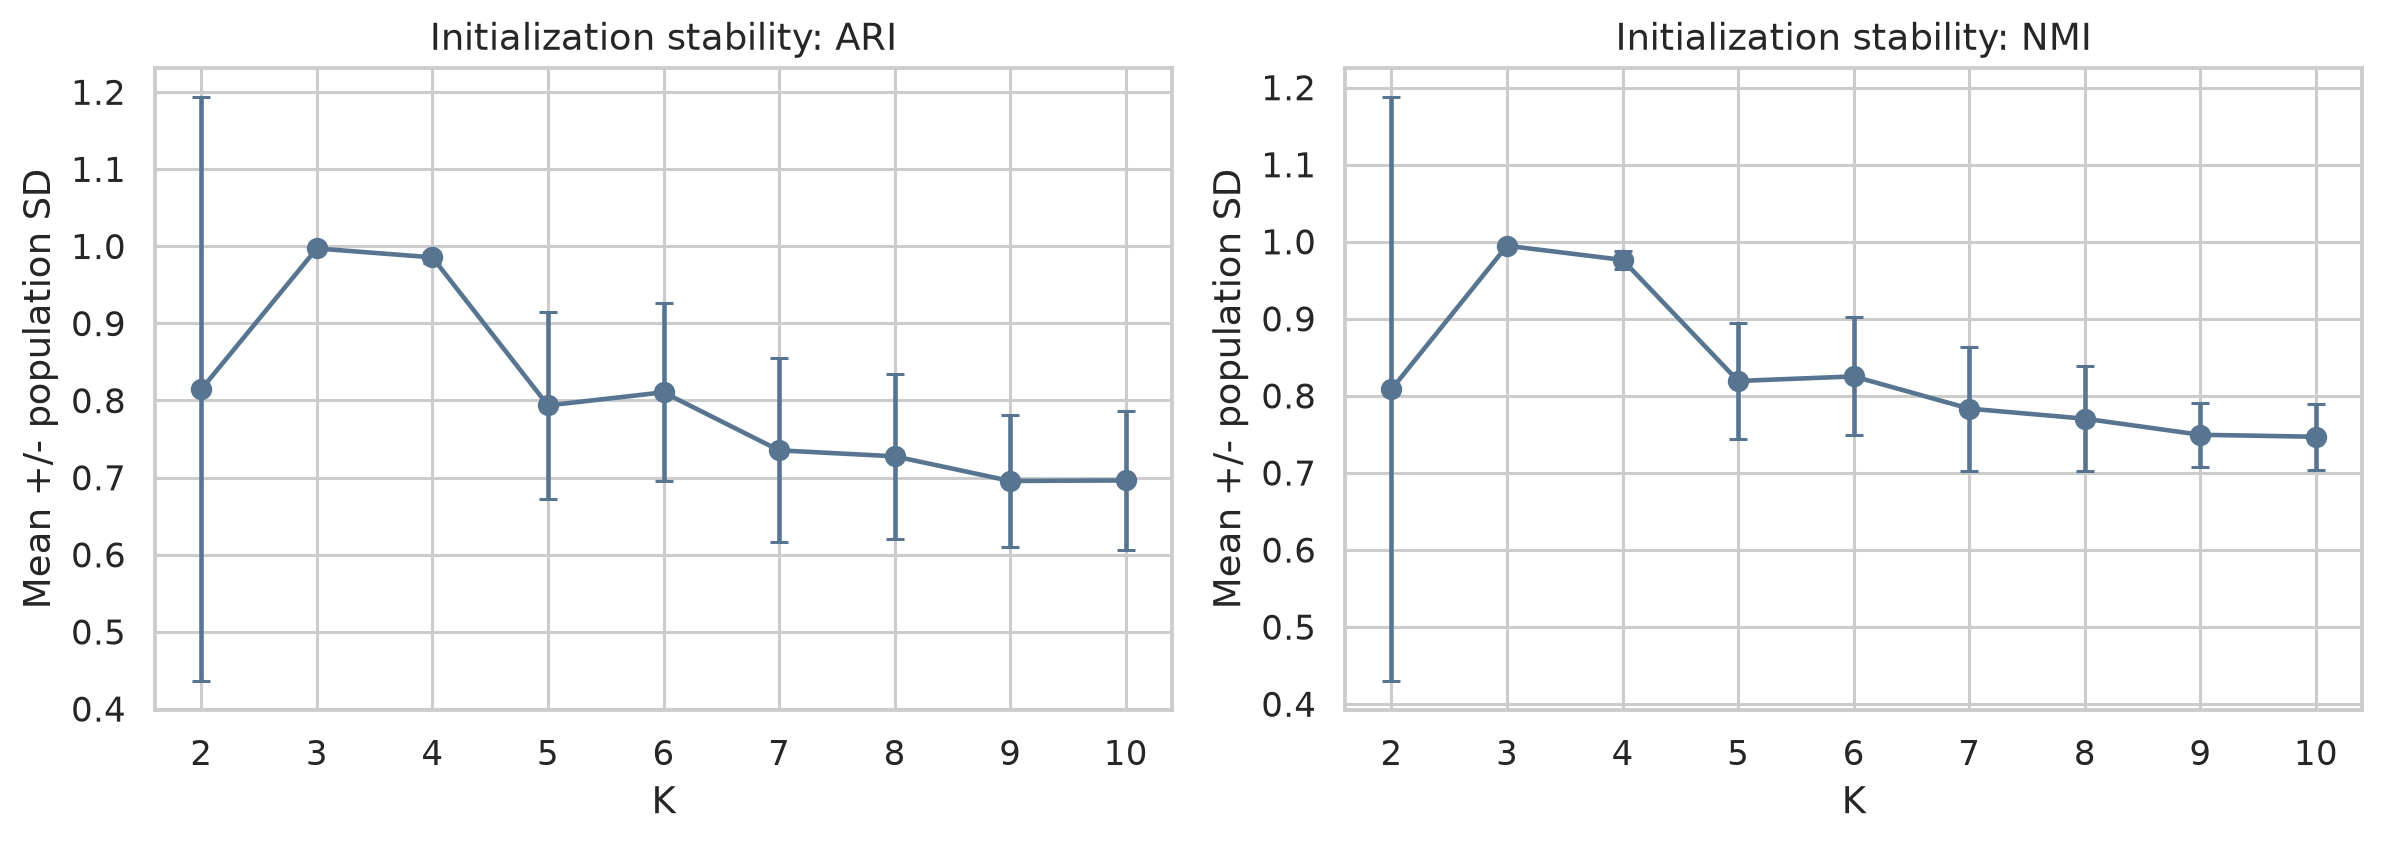

In [5]:
display(tables['kmeans_candidates'])
display(tables['final_kmeans_metrics'])
display(tables['kmeans_stability'])
show_figure('kmeans_candidates')
show_figure('initialization_stability')

## K=3 and K=4 profiles
Compare original-unit median profiles and actual customer memberships rather than using segment counts alone. K=3 combines purchasing-capacity patterns more broadly; the contingency table reveals where rows move between solutions.

In [6]:
for name in ['k3_sizes', 'k3_medians', 'k4_medians', 'k3_k4_contingency']:
    print(name.replace('_', ' ').title())
    display(tables[name])

K3 Sizes


,count,share
cluster,,
0,785,0.3925
1,781,0.3905
2,434,0.2170


K3 Medians


,age,monthly_income,num_children,spend_grocery,spend_fashion,spend_electronics,spend_dining,spend_online,visits_store_per_month,visits_online_per_month,loyalty_score
cluster,,,,,,,,,,,
0,40.0,9500.0,1.0,900.0,450.0,600.0,700.0,550.0,6.0,6.0,51.0
1,30.0,6400.0,0.0,500.0,600.0,600.0,600.0,900.0,2.0,13.0,55.0
2,38.0,3600.0,0.0,625.0,200.0,250.0,300.0,250.0,3.0,3.0,35.0


K4 Medians


,age,monthly_income,num_children,spend_grocery,spend_fashion,spend_electronics,spend_dining,spend_online,visits_store_per_month,visits_online_per_month,loyalty_score
cluster,,,,,,,,,,,
0,38.0,3550.0,0.0,600.0,200.0,250.0,300.0,250.0,3.0,3.0,34.0
1,42.0,8050.0,1.0,1000.0,400.0,500.0,600.0,500.0,6.0,5.0,47.0
2,30.0,6300.0,0.0,500.0,600.0,550.0,600.0,900.0,2.0,13.0,55.0
3,37.0,15550.0,0.0,750.0,650.0,750.0,900.0,700.0,6.0,10.0,57.0


K3 K4 Contingency


K4_cluster,0,1,2,3
K3_cluster,,,,
0,0,492,3,290
1,0,2,739,40
2,414,18,2,0


## Ward comparison


SciPy Euclidean/Ward linkage uses all 2,000 rows in the same five-PC representation. K=2 through K=8 are evaluated with `fcluster(..., criterion='maxclust')`. The dendrogram uses the complete tree without sampling. Cophenetic correlation describes correspondence between tree merge distances and original distances, not business validity.

| model               | silhouette   | CHI     | DBI   | minClusterRatio   |
|:--------------------|:-------------|:--------|:------|:------------------|
| K-Means (n_init=30) | 0.326        | 923.144 | 1.222 | 0.165             |
| Ward (SciPy)        | 0.305        | 844.971 | 1.267 | 0.116             |

The K=4 Ward profiles show broadly similar purchasing patterns after matching clusters by maximum customer-membership overlap. Matched median income is SGD 8,400 for the family pattern and SGD 15,725 for the higher-income pattern. Cross-method ARI/NMI is 0.823/0.787; memberships are similar, not identical. The aggregate contingency table and matched profiles expose the differences. SciPy and sklearn Euclidean/Ward partitions are equivalent up to relabeling at K=4 in this environment (ARI=NMI=1).

Ward stability uses 10 independent 80% subsets, seeds 64 through 73, compared to the full-data Ward partition restricted to each subset's indices. At K=4 mean ARI/NMI is 0.826/0.813, with SD 0.031/0.017 (`ddof=0`). This reference scheme and run count differ from K-Means. Ward's silhouette uses 2,000 customers while K-Means uses 1,000; neither the silhouette nor stability gap is a fully controlled comparison. These observed results support K-Means as a practical working segmentation, with no universal claim that Ward is more or less stable or robust. Both methods assign extremes to groups rather than identifying noise. A fitted K-Means model could assign future customers after matching preprocessing; no production assignment or drift monitoring system has been implemented or validated.

Ward Candidates


,K,copheneticCorr,silhouette,CHI,DBI,minClusterRatio
0,2,0.62,0.288876,735.769603,0.998175,0.197
1,3,0.62,0.323287,963.777391,1.186258,0.197
2,4,0.62,0.305277,844.970902,1.266798,0.116
3,5,0.62,0.259637,740.570338,1.492177,0.116
4,6,0.62,0.212031,641.767653,1.850592,0.102
5,7,0.62,0.198947,576.601691,1.844859,0.064
6,8,0.62,0.198900,527.973454,1.789916,0.064


Ward Stability


,K,ARI_mean,ARI_std,NMI_mean,NMI_std
0,2,0.995960,0.003907,0.987898,0.010780
1,3,0.918218,0.031278,0.900644,0.023682
2,4,0.826274,0.030642,0.813448,0.017484
3,5,0.705923,0.046338,0.748127,0.026564
4,6,0.667510,0.021615,0.715752,0.018385
5,7,0.632195,0.031846,0.686761,0.024332
6,8,0.647972,0.044400,0.689661,0.030596


Ward Sizes


,count,share
cluster,,
0,394,0.1970
1,753,0.3765
2,232,0.1160
3,621,0.3105


... (6 outputs left out)

Partition Agreement


,comparison,ARI,NMI
0,candidate20_vs_final30_K4,1.000000,1.000000
1,candidate20_vs_final30_K3,1.000000,1.000000
2,SciPy_vs_sklearn_Ward_K4,1.000000,1.000000
3,KMeans_vs_Ward_K4,0.823369,0.786932


Cross Method Contingency


Ward_cluster,0,1,2,3
KMeans_cluster,,,,
0,394,8,0,12
1,0,3,5,504
2,0,721,9,14
3,0,21,218,91


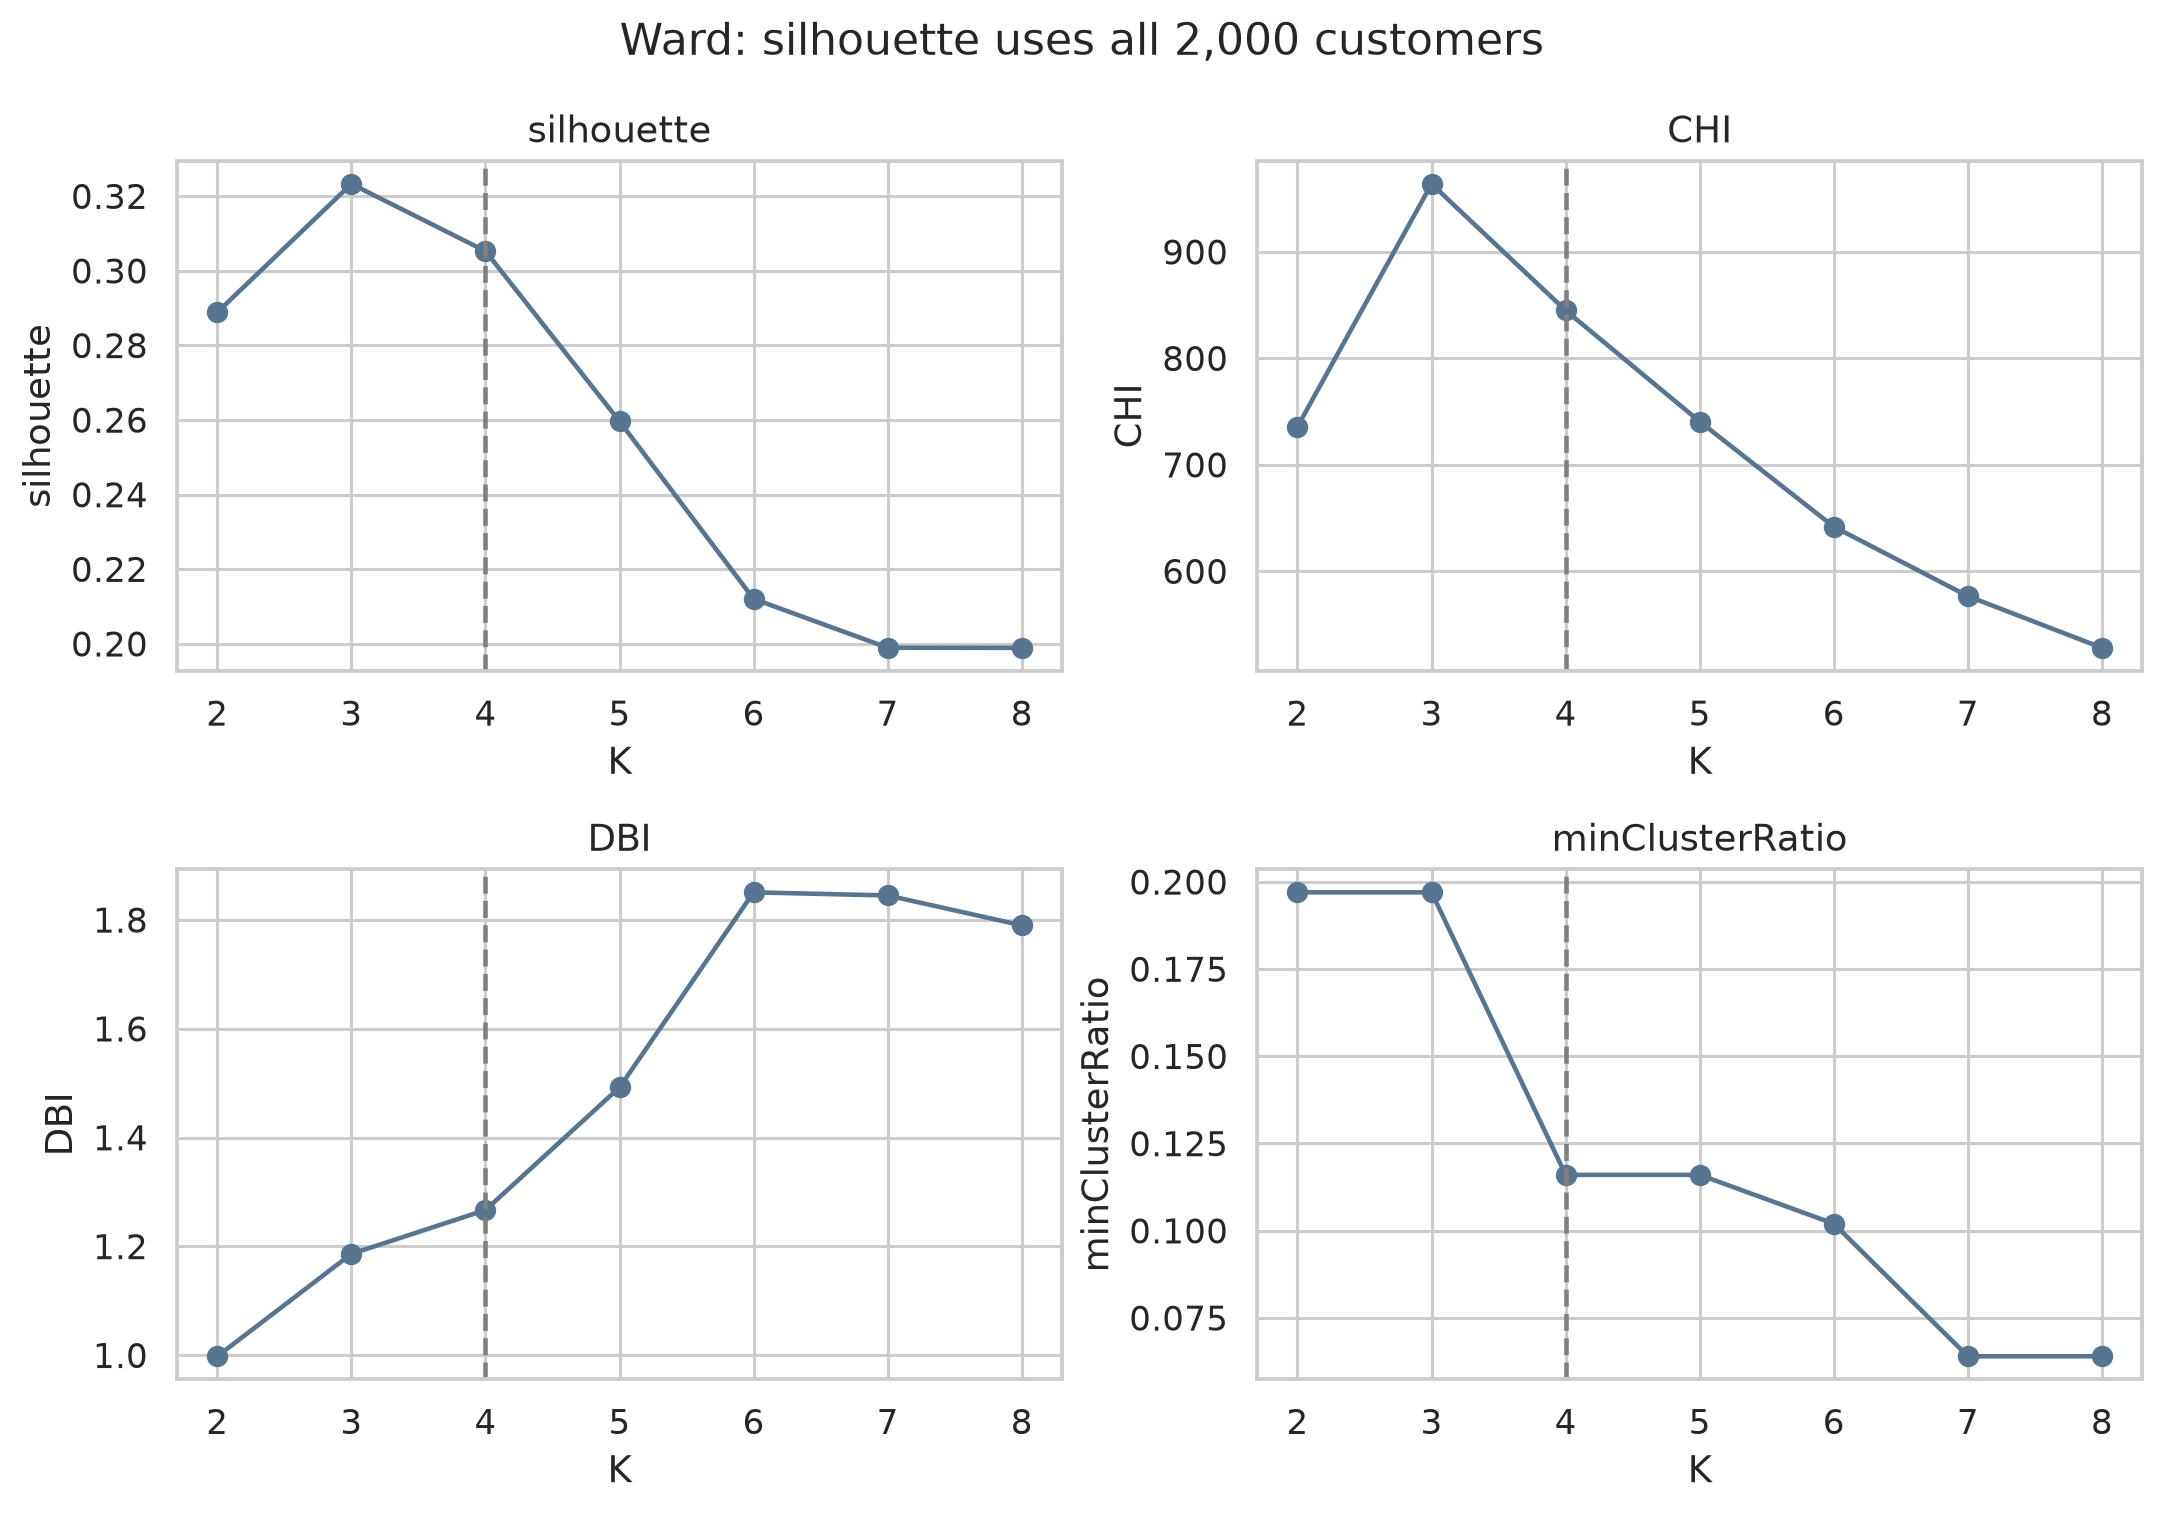

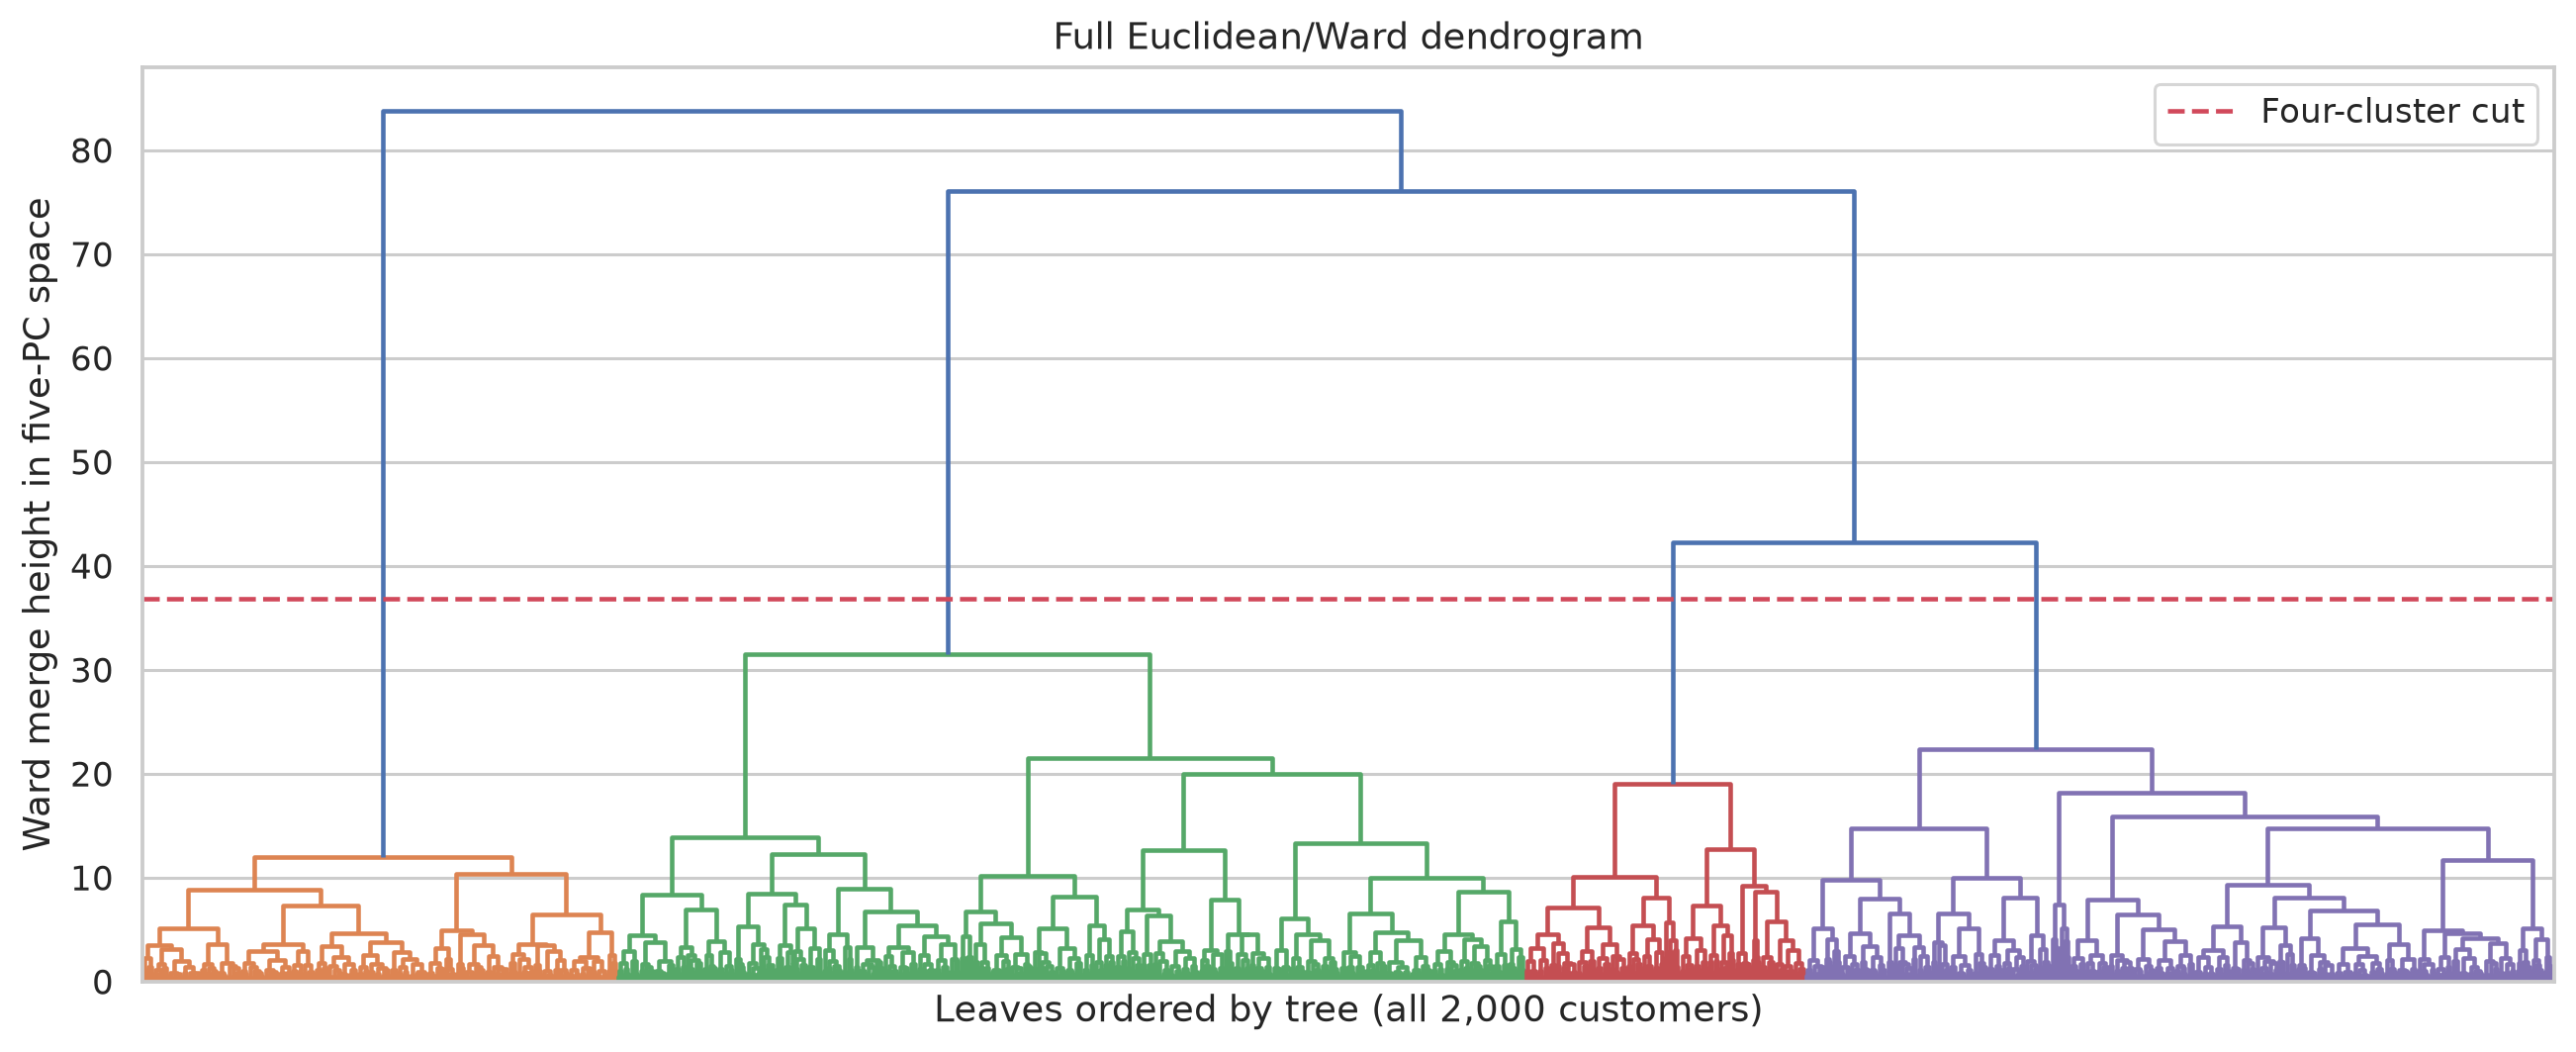

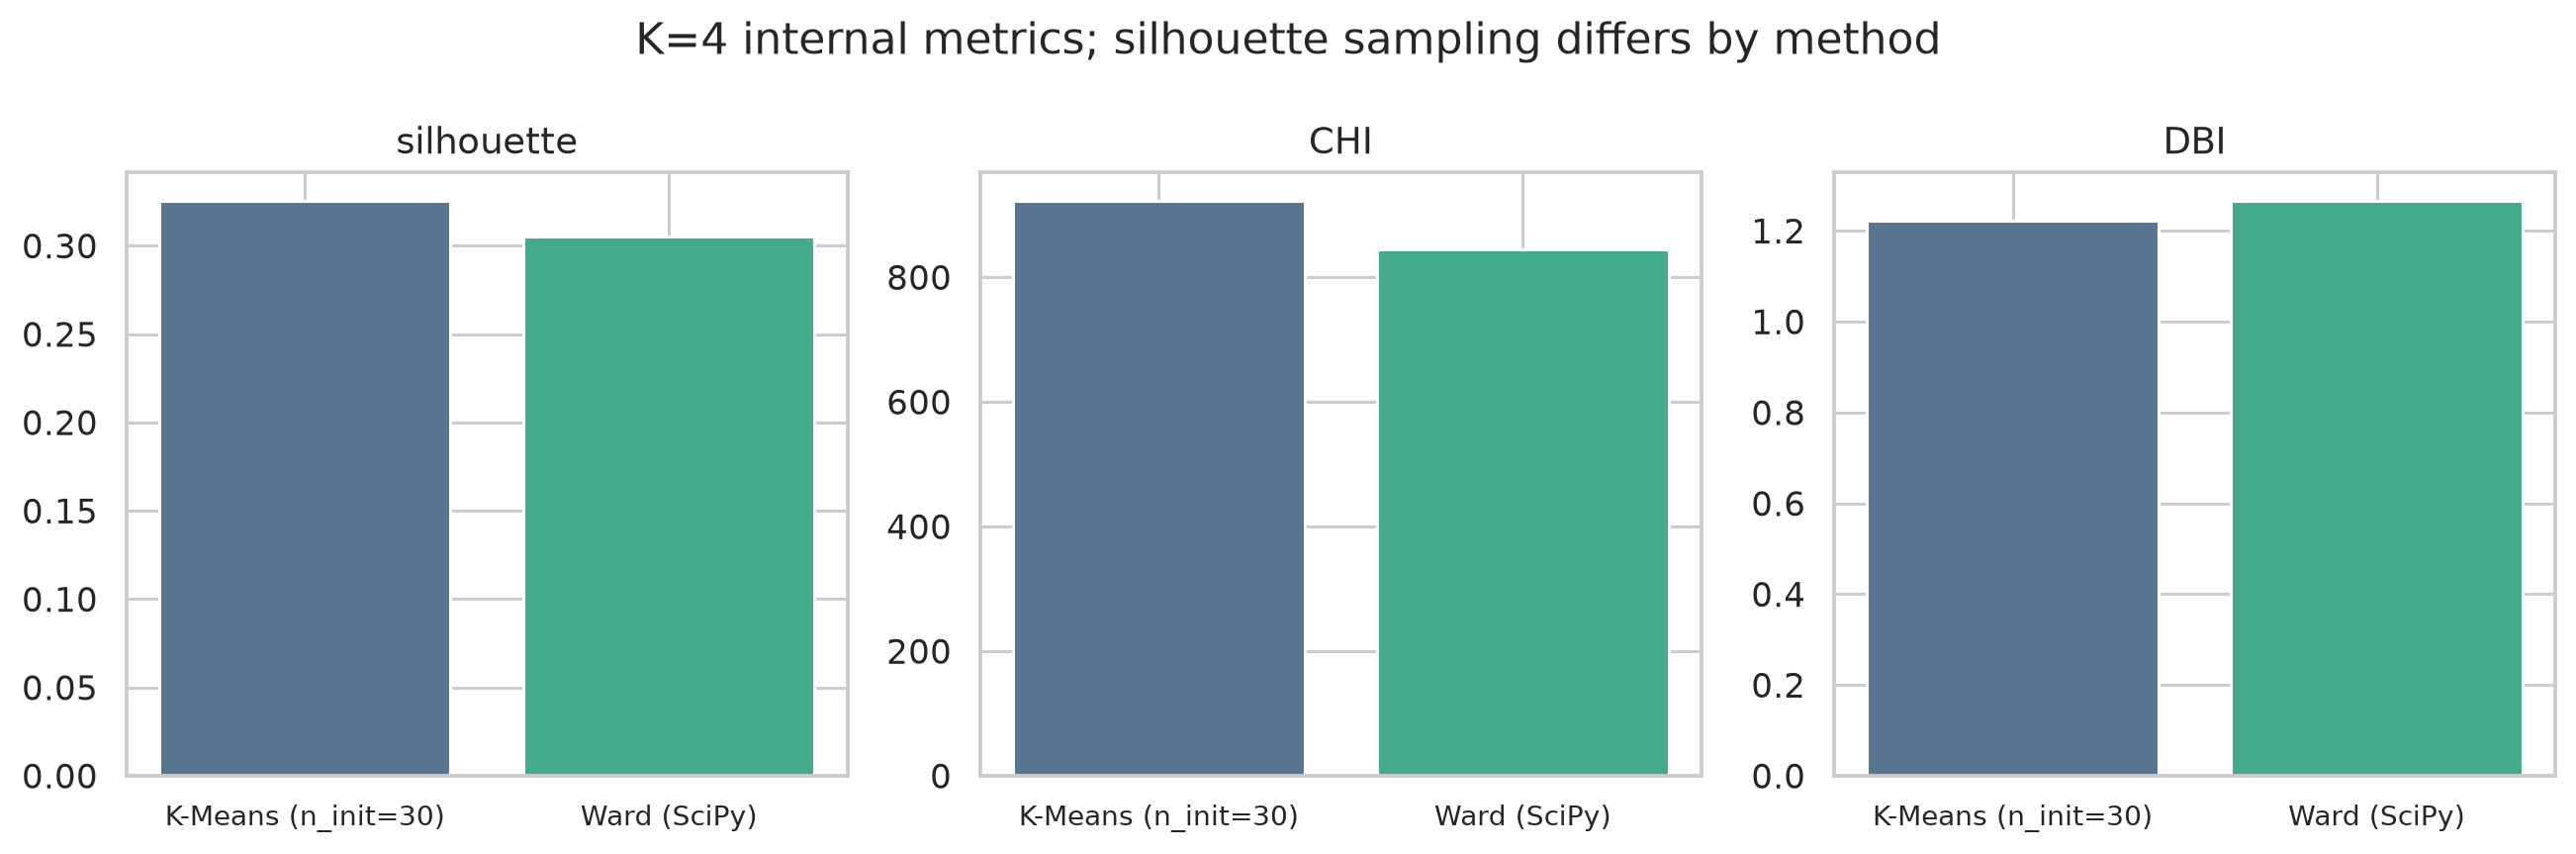

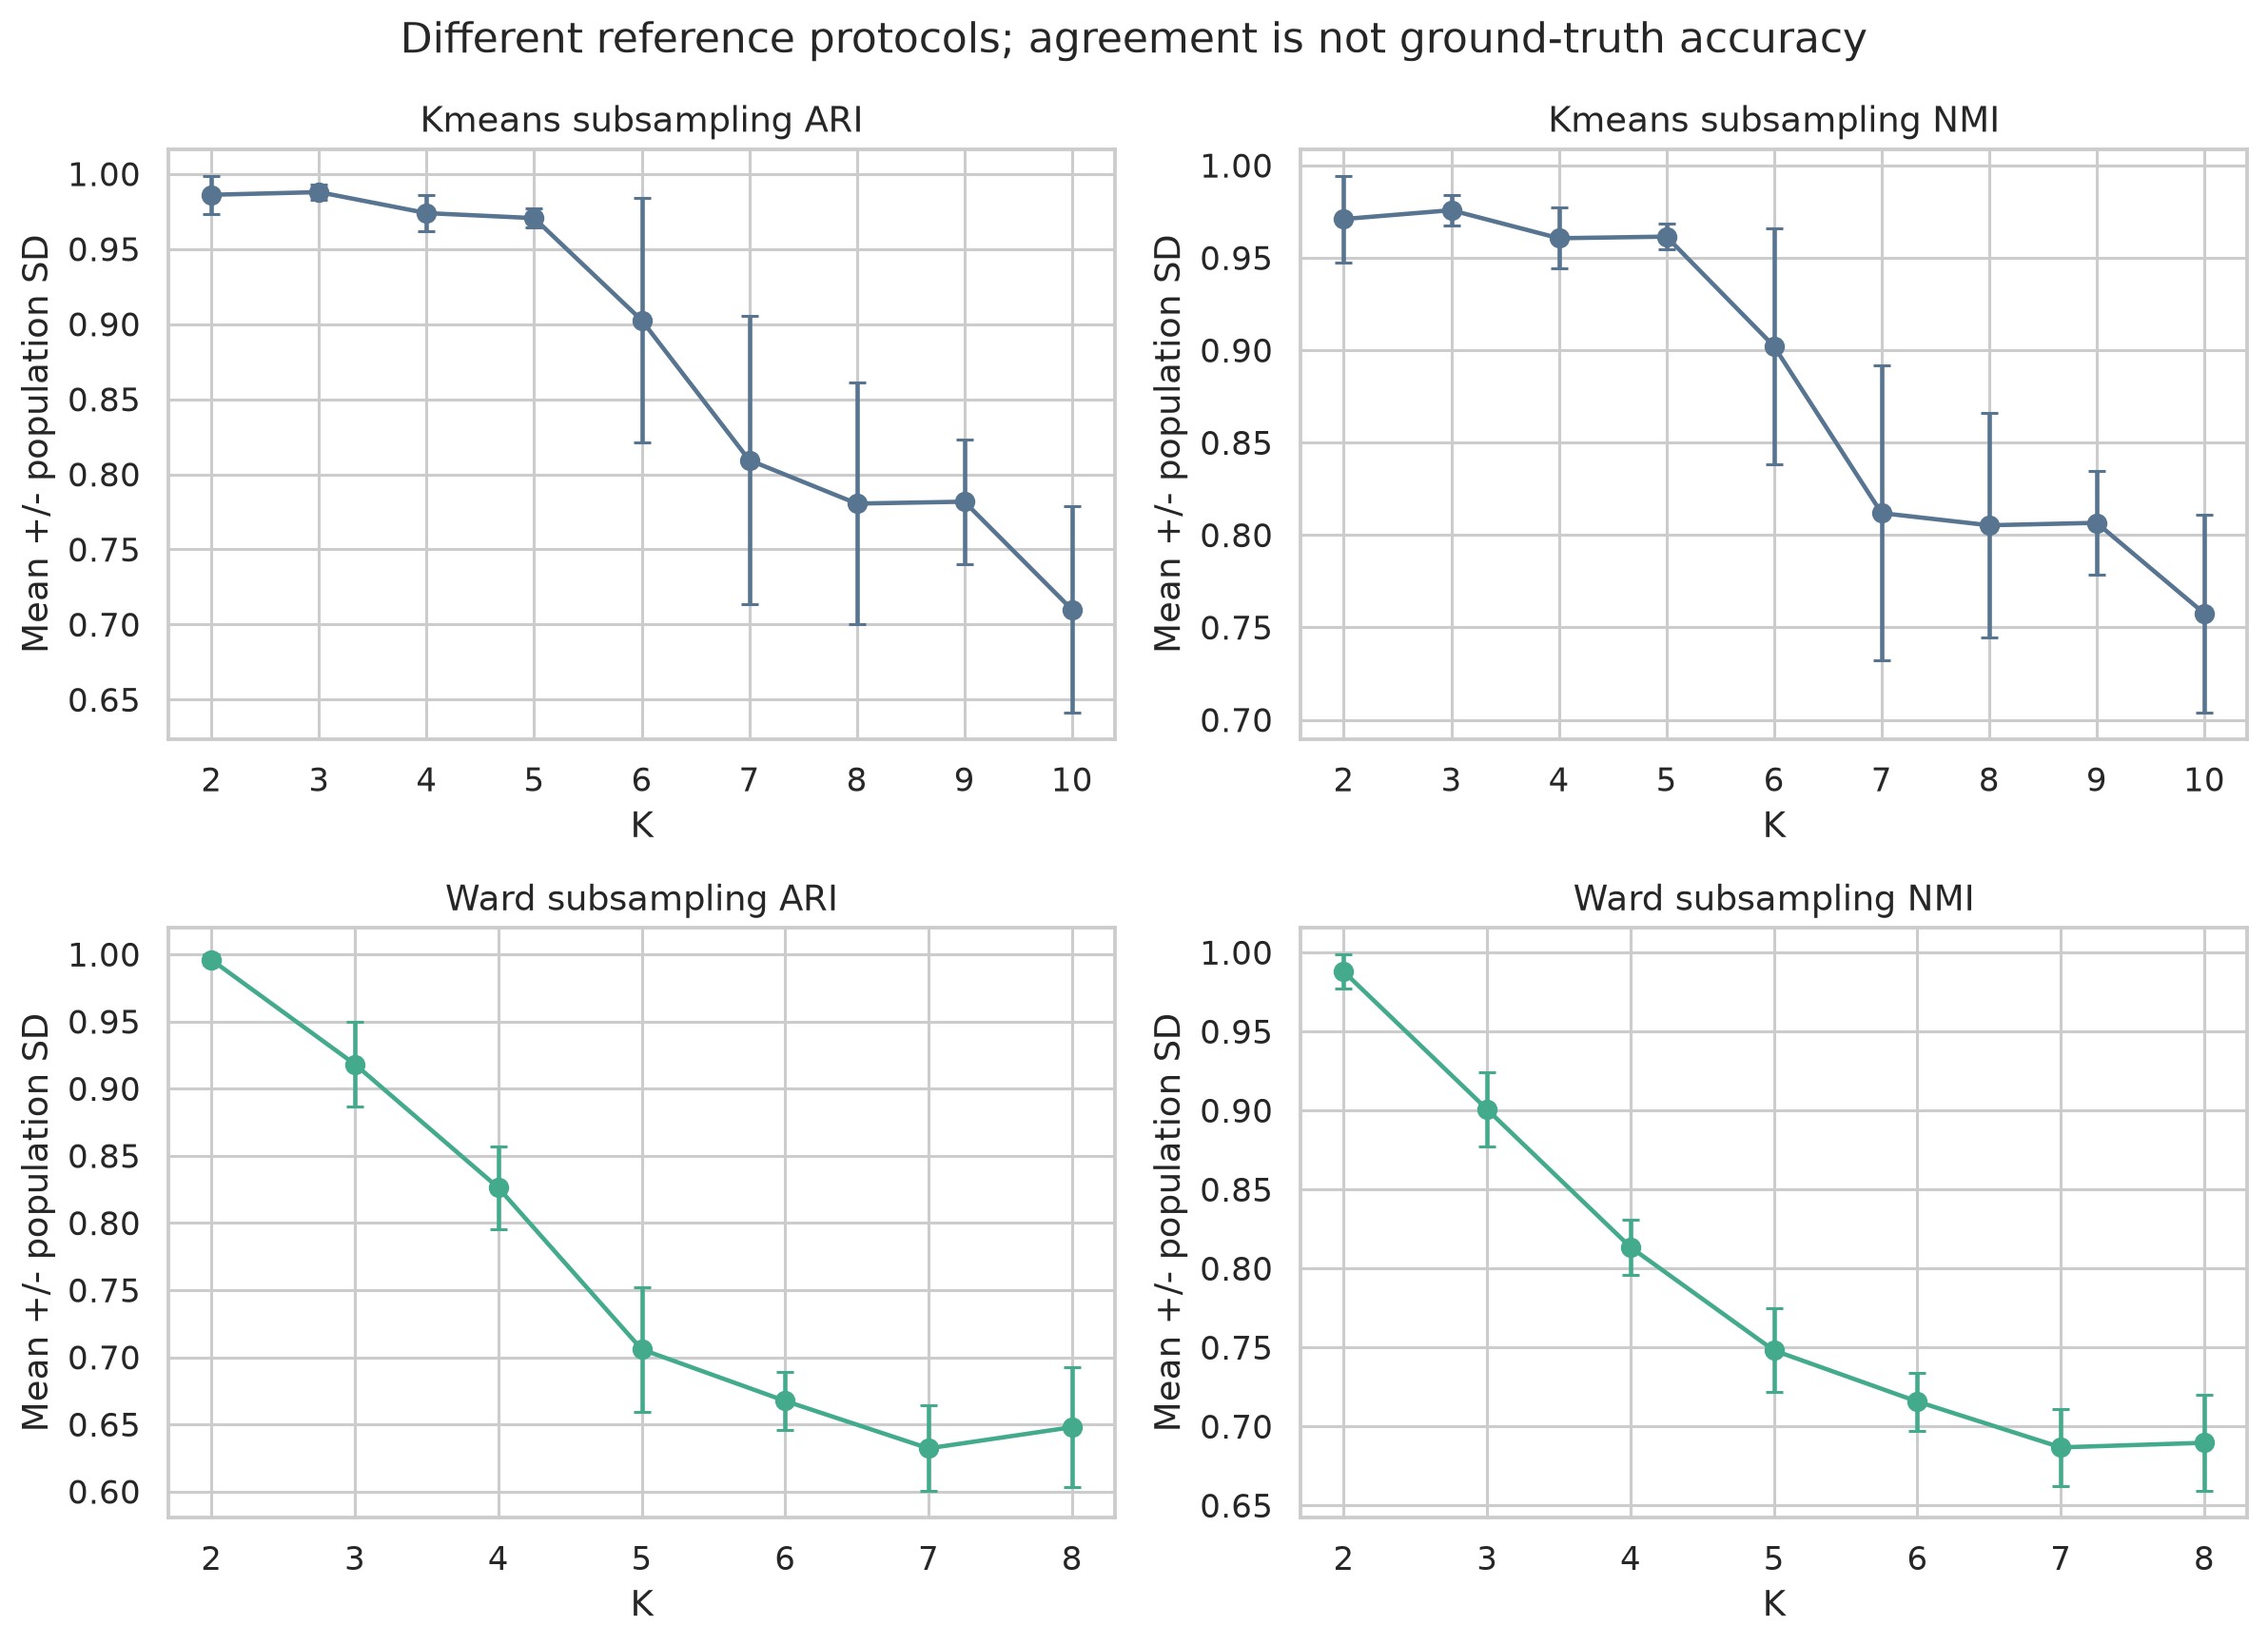

In [7]:
for name in ['ward_candidates', 'ward_stability', 'ward_sizes', 'ward_medians',
             'ward_matched_medians', 'model_comparison', 'partition_agreement', 'cross_method_contingency']:
    print(name.replace('_', ' ').title())
    display(tables[name])
for name in ['ward_candidates', 'ward_dendrogram', 'model_comparison', 'stability']:
    show_figure(name)

## Customer profiles

Counts and shares use all 2,000 customers. Numeric profiles below are within-segment medians in original units after imputation. Separate exported tables provide means and categorical modes; categorical proportion tables provide counts, denominators and shares for every observed level. Medians summarize each feature separately and do not represent a single customer.

| Segment                          | Customers   | Share   | Median income (SGD/month)   | Median store visits/month   | Median online visits/month   |
|:---------------------------------|:------------|:--------|:----------------------------|:----------------------------|:-----------------------------|
| Low-engagement shoppers          | 414         | 20.7%   | 3,550                       | 3                           | 3                            |
| Family-focused shoppers          | 512         | 25.6%   | 8,050                       | 6                           | 5                            |
| Fashion and technology shoppers  | 744         | 37.2%   | 6,300                       | 2                           | 13                           |
| High-income omnichannel shoppers | 330         | 16.5%   | 15,550                      | 6                           | 10                           |

Median category and online spending (SGD per month; columns may overlap):

| Segment                          | Grocery   | Fashion   | Electronics   | Dining   | Online   |
|:---------------------------------|:----------|:----------|:--------------|:---------|:---------|
| Low-engagement shoppers          | 600       | 200       | 250           | 300      | 250      |
| Family-focused shoppers          | 1,000     | 400       | 500           | 600      | 500      |
| Fashion and technology shoppers  | 500       | 600       | 550           | 600      | 900      |
| High-income omnichannel shoppers | 750       | 650       | 750           | 900      | 700      |

Low-engagement shoppers have the lowest median income and low spending and channel visits. Family-focused shoppers have higher grocery spending, a median of one child and 68.4% married customers (350/512); the name describes an observed pattern rather than every household. Fashion and technology shoppers have median age 30, stronger fashion/electronics spending than the low-engagement and family groups, the highest online spending and online visits, and fewer store visits. High-income omnichannel shoppers have the highest median income, high spending across several categories, and substantial activity in both channels. Income and spending are not profit or lifetime value.

Demographics should qualify the profiles. In the fashion/technology segment, married customers comprise 47.2% (351/744) and single customers 45.2% (336/744), so it is not predominantly single. The high-income segment is 52.7% male (174/330), a modest majority. Educational distributions are reported without assigning personality or motives. General online visits do not reveal social-media platform use.




The heatmap first computes segment medians in original units, then standardizes each feature across the four medians using sample SD (`ddof=1`). It is not a customer-level standardized mean heatmap. Read the original-unit table for spending and visits. PC1/PC2 charts are two-dimensional projections of a five-PC clustering solution; projected separation does not show the full model geometry.

Segment Overview


,segment,count,share,age,monthly_income,num_children,spend_grocery,spend_fashion,spend_electronics,spend_dining,spend_online,visits_store_per_month,visits_online_per_month,loyalty_score
cluster,,,,,,,,,,,,,,
0,Low-engagement shoppers,414,0.207,38.0,3550.0,0.0,600.0,200.0,250.0,300.0,250.0,3.0,3.0,34.0
1,Family-focused shoppers,512,0.256,42.0,8050.0,1.0,1000.0,400.0,500.0,600.0,500.0,6.0,5.0,47.0
2,Fashion and technology shoppers,744,0.372,30.0,6300.0,0.0,500.0,600.0,550.0,600.0,900.0,2.0,13.0,55.0
3,High-income omnichannel shoppers,330,0.165,37.0,15550.0,0.0,750.0,650.0,750.0,900.0,700.0,6.0,10.0,57.0


K4 Means


,age,monthly_income,num_children,spend_grocery,spend_fashion,spend_electronics,spend_dining,spend_online,visits_store_per_month,visits_online_per_month,loyalty_score
cluster,,,,,,,,,,,
0,37.780193,3706.763285,0.683575,614.371981,213.405797,257.263347,312.922705,261.130056,2.543478,3.318841,34.524155
1,41.695312,9118.253906,1.523438,998.046875,400.292969,513.539663,605.468750,502.737697,7.978516,5.166016,47.160156
2,30.517473,6419.086022,0.280914,503.629032,620.497312,569.575338,608.669355,890.314997,2.336022,12.858871,55.528226
3,37.257576,20174.966667,0.848485,782.121212,628.333333,740.720124,916.515152,680.637750,7.266667,10.109091,57.072727


K4 Modes


,gender,marital_status,education_level
cluster,,,
0,Female,Married,Bachelor
1,Female,Married,Bachelor
2,Female,Married,Bachelor
3,Male,Married,Bachelor


K4 Proportions


,cluster,category,count,denominator,share,field
0,0,Female,222,414,0.536232,gender
1,0,Male,192,414,0.463768,gender
2,1,Female,266,512,0.519531,gender
3,1,Male,246,512,0.480469,gender
4,2,Female,394,744,0.529570,gender
5,2,Male,350,744,0.470430,gender
6,3,Female,156,330,0.472727,gender
7,3,Male,174,330,0.527273,gender
8,0,Divorced,50,414,0.120773,marital_status
9,0,Married,245,414,0.591787,marital_status


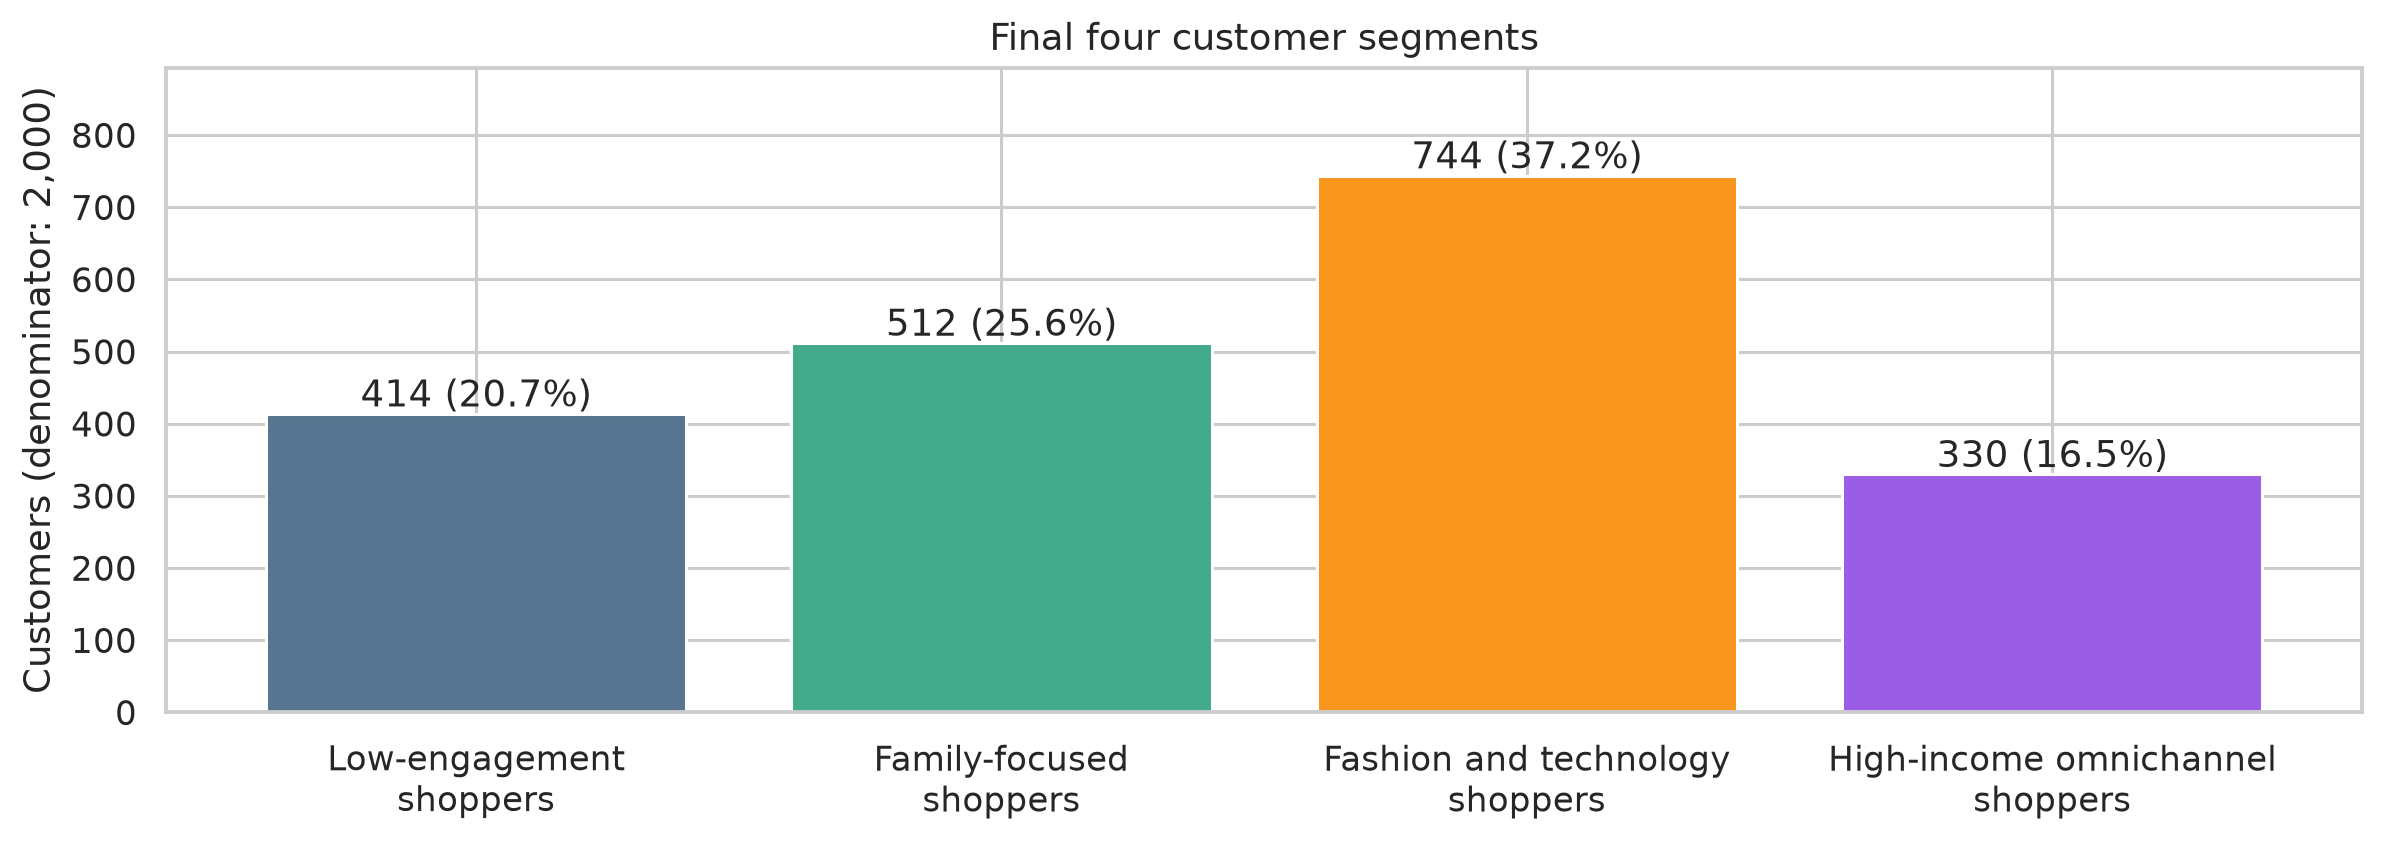

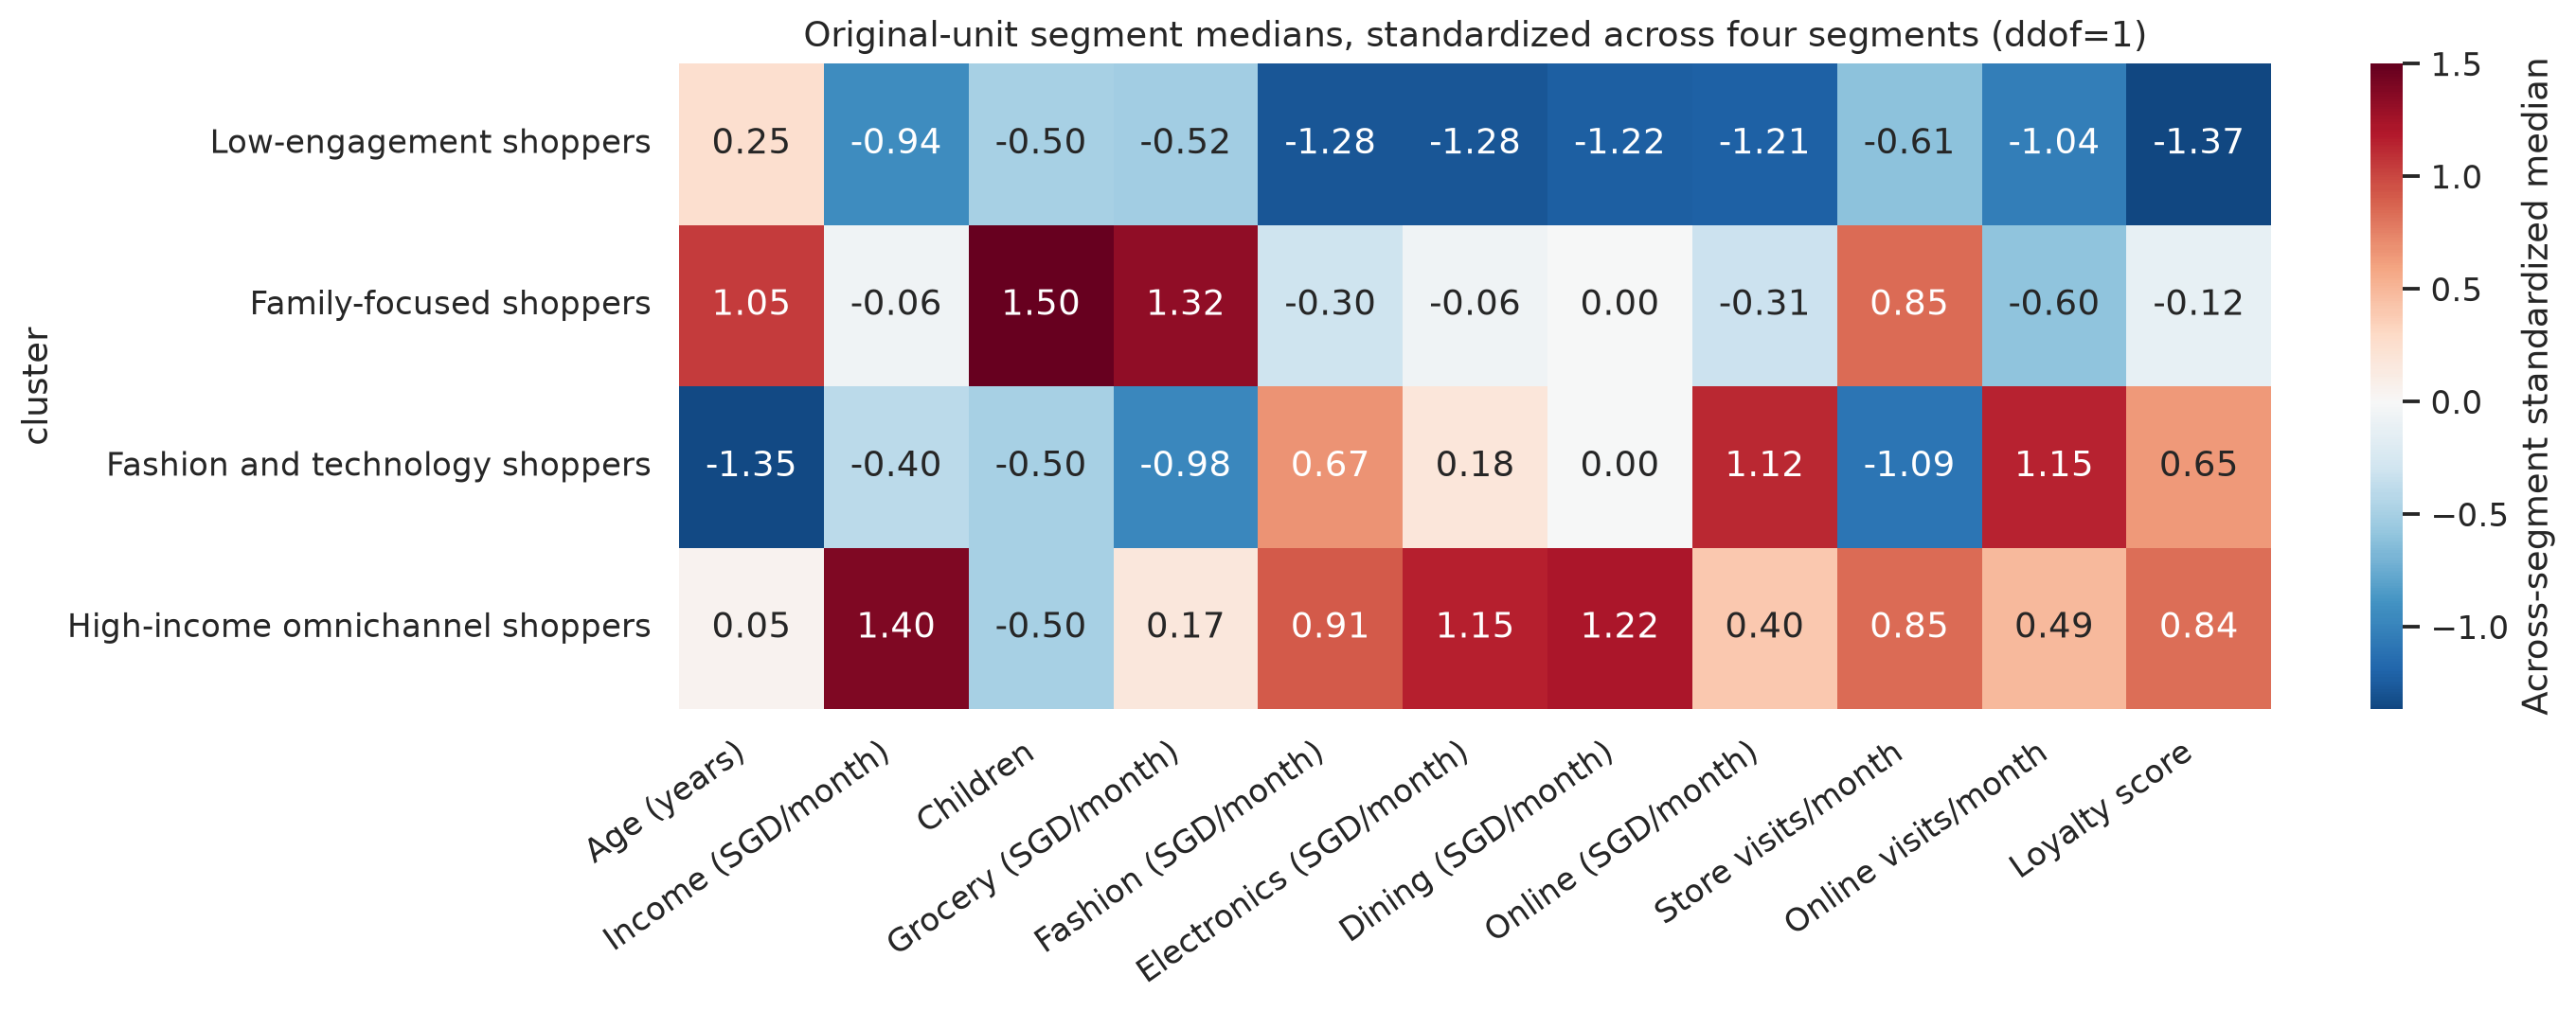

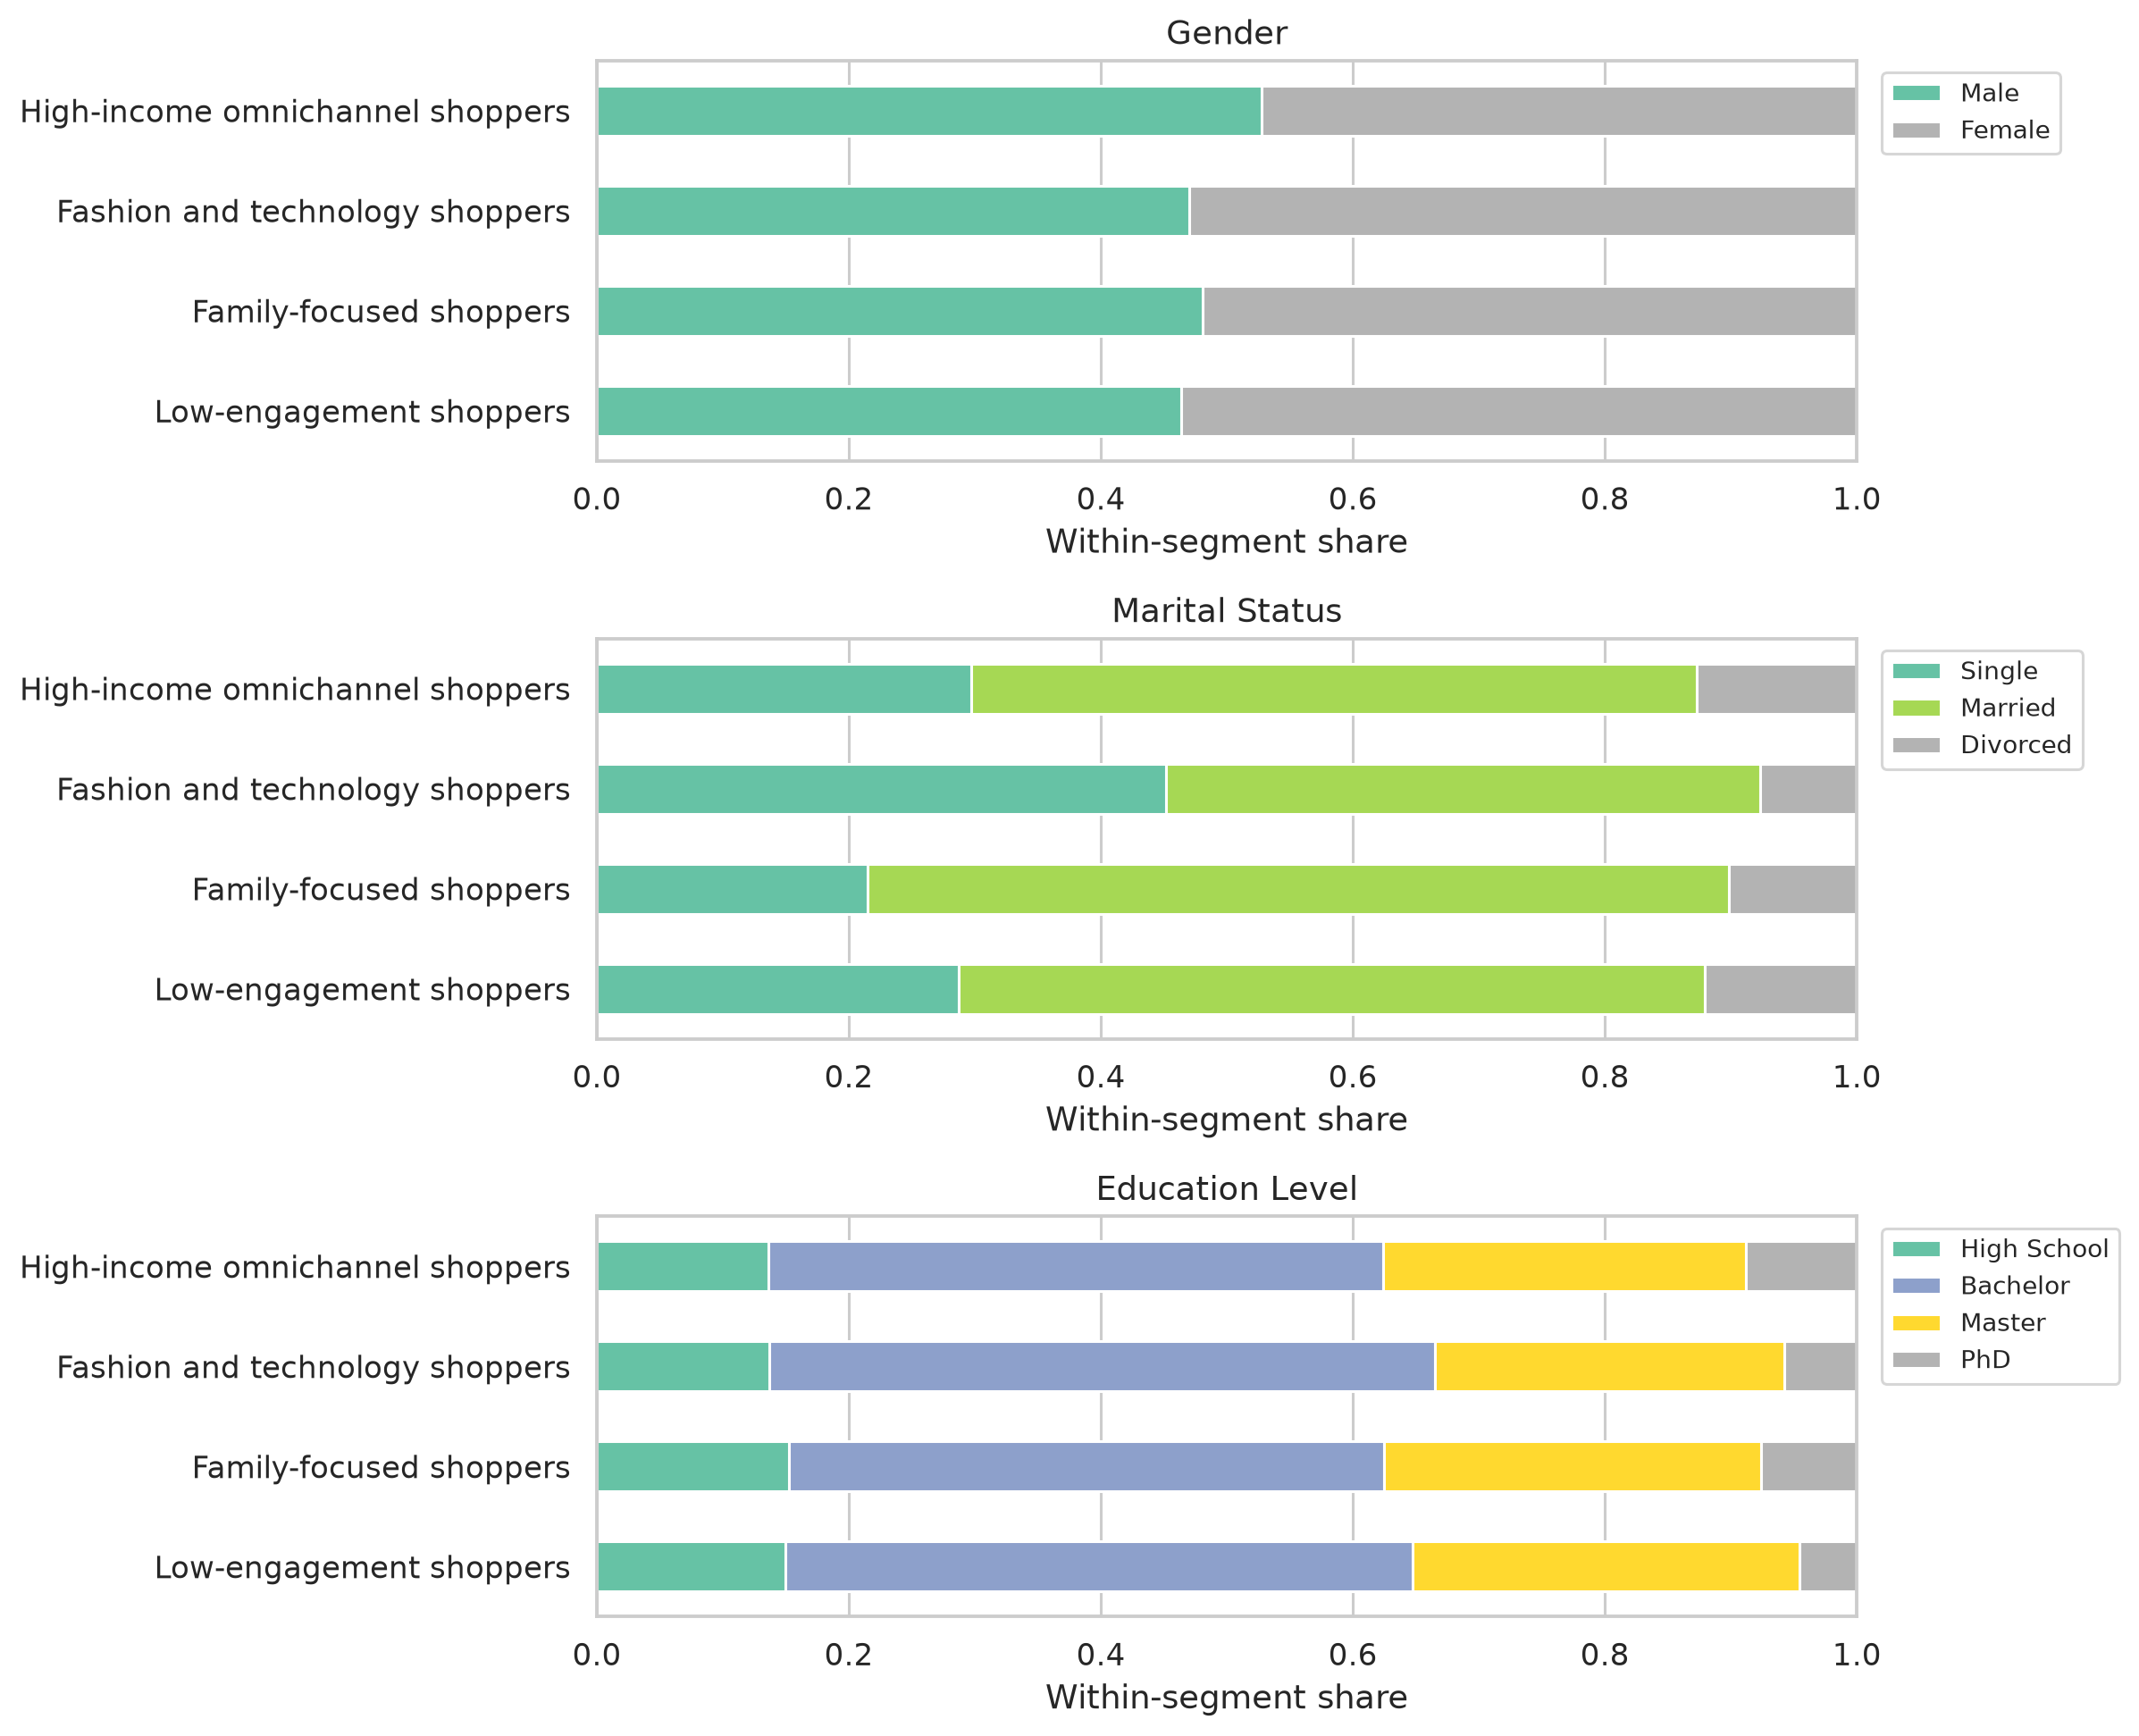

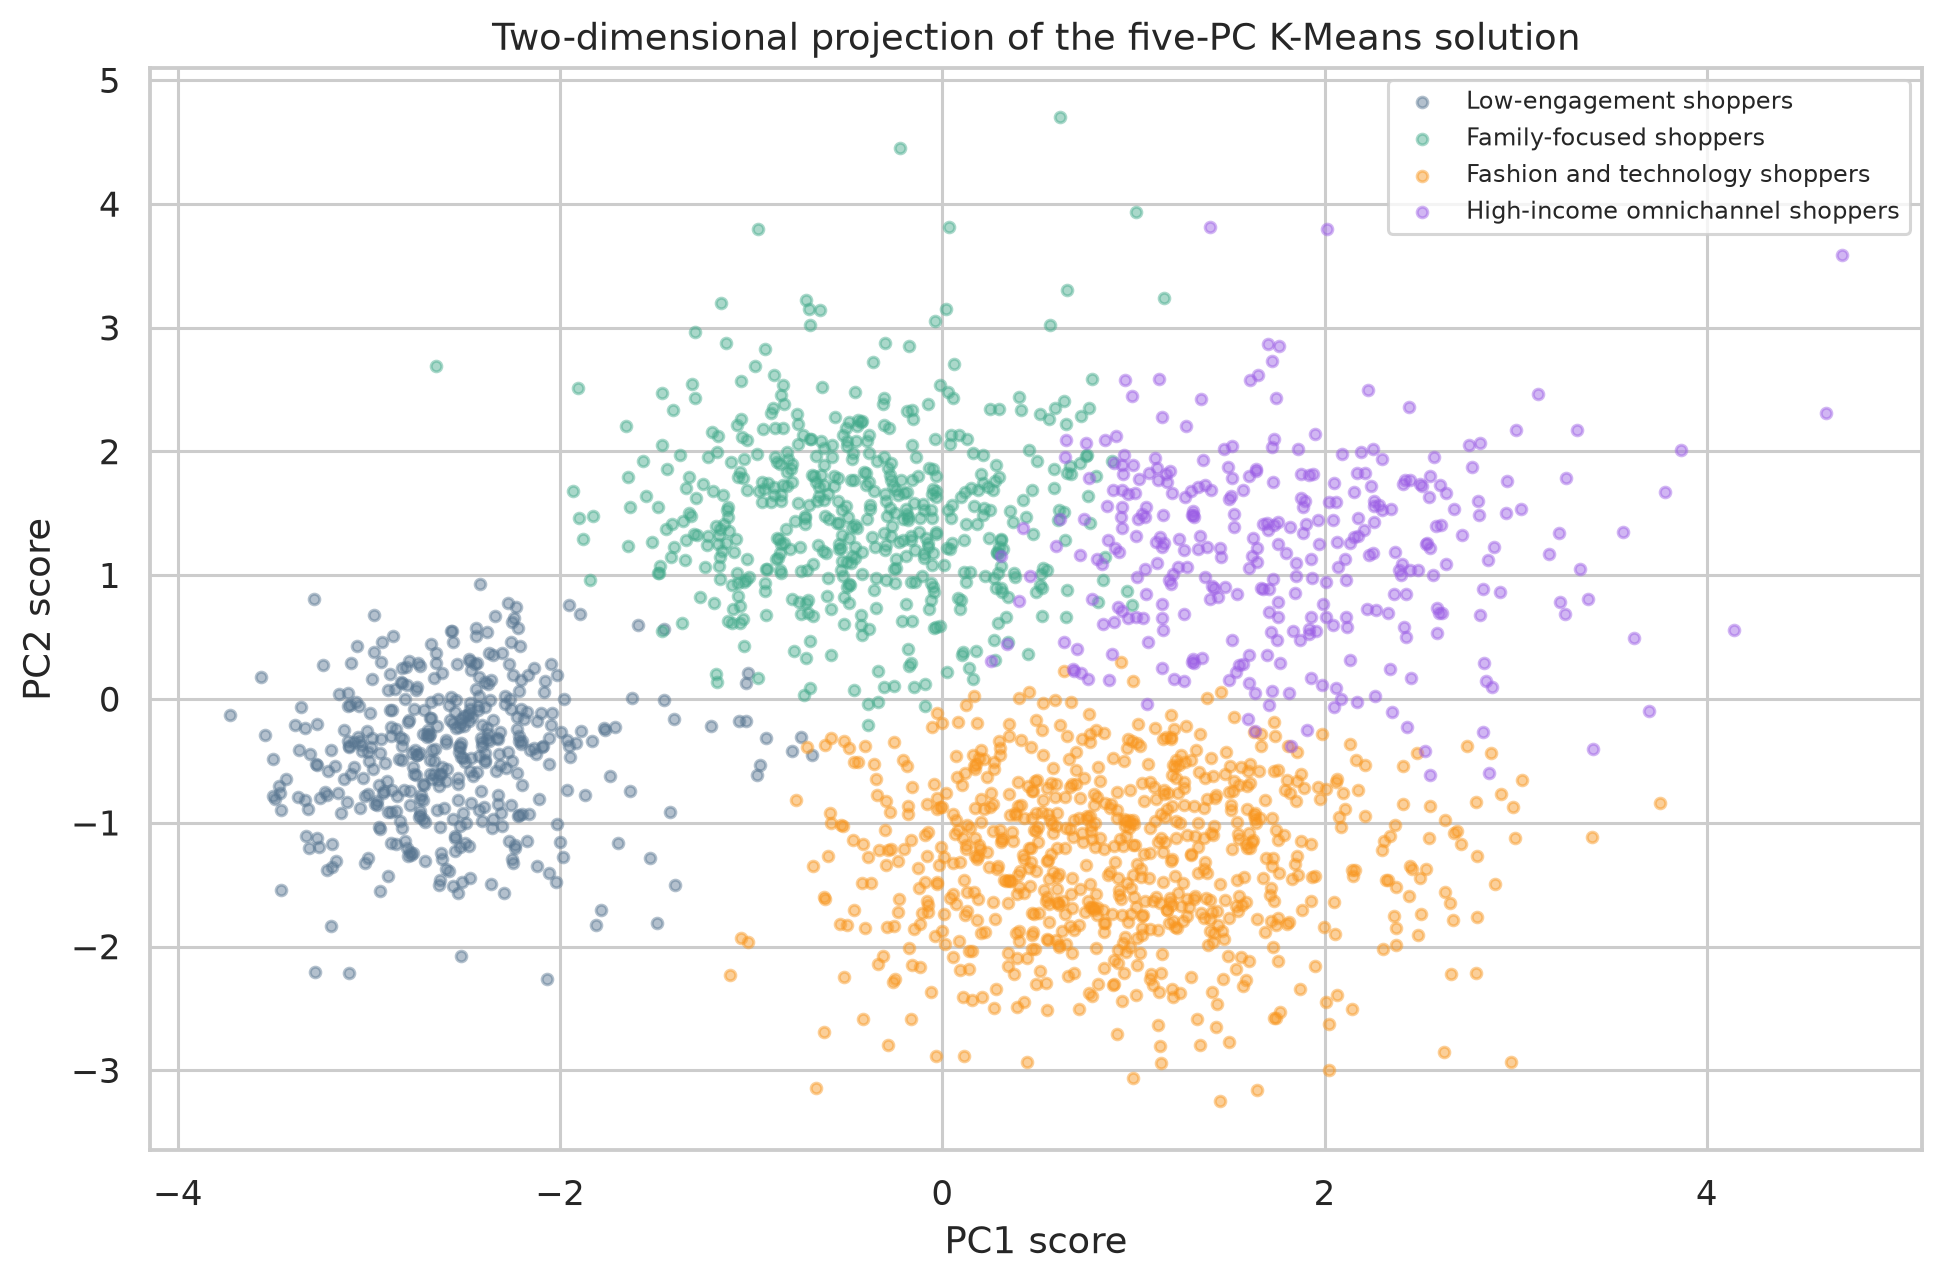

In [8]:
for name in ['segment_overview', 'k4_means', 'k4_modes', 'k4_proportions']:
    print(name.replace('_', ' ').title())
    display(tables[name])
for name in ['segment_sizes', 'profile_heatmap', 'demographic_proportions', 'segment_projection']:
    show_figure(name)

## Key findings and business implications

### 1. The largest segment provides a clear online targeting hypothesis

Fashion and technology shoppers account for **744 customers (37.2%)**. They have median online spending of **SGD 900 per month** and **13 online visits**, compared with **2 store visits**. This is the largest segment and has the highest median online spending and online visits among the four groups.

For the simulated marketing brief, these observations justify testing category recommendations or relevant bundles on the retailer's online platform. They do not establish conversion rates or use of particular social platforms. A proposed first pilot would evaluate category-purchase conversion and repeat online purchase, with margin as a guardrail once cost data is available.

### 2. Category needs and purchasing capacity support separate offer hypotheses

Family-focused shoppers have the highest median grocery spending, **SGD 1,000 per month**, and a median of **1 child**. High-income omnichannel shoppers instead have median income of **SGD 15,550**, dining spending of **SGD 900**, and **6 store / 10 online visits** per month.

These profiles motivate different hypotheses: grocery replenishment or bundles for the family-focused pattern, and coordinated cross-channel benefits or service options for the high-income omnichannel pattern. The extra K=4 distinction has a business use only if it leads to different offers and improves outcomes in testing. Higher income and spending do not establish higher profitability.

### 3. Low engagement identifies a group for a repeat-purchase test

Low-engagement shoppers comprise **414 customers (20.7%)**, with median **3 store visits, 3 online visits** and monthly income of **SGD 3,550**. Median fashion, electronics and dining spending are lower than in each of the other three groups.

This supports testing a simple, relevant repeat-visit offer through an available consented retailer channel. Their low activity is an observed cross-sectional pattern. Longitudinal purchases are needed to estimate churn, and cost data is needed to evaluate discount profitability.

### 4. A useful working segmentation requires a model-selection tradeoff

K=3 has a higher silhouette (**0.336**) than K=4 (**0.326**), as well as better CH and DB scores. K=4 is retained because the grocery/family and high-income omnichannel profiles suggest distinct decisions. The recommendation combines numerical evidence with interpretability; it does not claim K=4 is the statistical optimum or that four-group targeting has already improved sales.

## Recommended pilots and measurement plan

| Segment | Evidence-led hypothesis | Proposed action and channel | Proposed primary metric |
| --- | --- | --- | --- |
| Low-engagement shoppers | A relevant prompt could encourage another purchase | Simple repeat-visit offer via an available consented retailer communication channel and in-store checkout | Repeat purchase rate |
| Family-focused shoppers | Grocery-oriented offers may be more relevant to this purchasing pattern | Grocery bundles or replenishment reminders through stores and consented retailer messaging | Grocery repeat purchase rate |
| Fashion and technology shoppers | Recommendations could match observed online category interest | Fashion/electronics recommendations or bundles on the retailer's online platform | Category-purchase conversion |
| High-income omnichannel shoppers | Coordinated benefits could support activity across channels | Cross-channel membership benefits or service options via the retailer's stores and online platform | Cross-channel repeat purchase rate |

**Proposed pilot priority:** start with online category recommendations if exposure tracking and random assignment are feasible. The largest segment has a clear channel signal and a measurable on-platform intervention. This is a proposed starting point based on segment size and behavior, not a forecast of the highest ROI. Operational effort, consent, costs and sample-size requirements could change the priority.

Before launch, define eligible customers, the primary metric, randomization unit, observation window and required sample size. Compare assigned treatment and control customers over the same period, including customers who do not respond. Report the difference with uncertainty rather than counting only offer redemptions. Track discounts, fulfillment/service costs and returns so that increased purchases can be assessed alongside incremental margin.

Customer-level transactions are needed for repeat purchase and retention; recommendation exposures and purchases are needed for conversion; cost and return records are needed for margin. None of these outcomes is measured by the current customer-level summary dataset. No achieved campaign results, baseline rates or numerical targets are claimed. If family and high-income groups receive different offers, a later test can compare the K=4 targeting strategy with the simpler K=3 strategy.


### Proposed KPI definitions

The following is a specification for future campaign measurement. These metrics are not computed from the current snapshot. Define eligibility and a common observation window before assignment, and count distinct customers consistently in each test arm.

| Proposed KPI | Numerator | Denominator | Additional data required |
| --- | --- | --- | --- |
| Repeat purchase rate | Eligible prior purchasers assigned to an arm who make at least one qualifying purchase during the test window | All eligible prior purchasers assigned to that arm | Baseline and test-period customer-level transactions, purchase dates and assignment records |
| Grocery repeat purchase rate | Eligible prior grocery purchasers assigned to an arm who make a qualifying grocery purchase during the test window | All eligible prior grocery purchasers assigned to that arm | Category-coded transactions, baseline grocery purchases and assignment records |
| Category-purchase conversion | Eligible customers assigned to an arm who buy the promoted fashion/electronics category during the test window | All eligible customers assigned to that arm | Category-coded purchases, assignment records and recommendation-exposure logs for diagnostic checks |
| Cross-channel repeat purchase rate | Eligible prior purchasers assigned to an arm who make qualifying purchases in both physical and online channels during the test window | All eligible prior purchasers assigned to that arm | Linked customer identities, channel-coded purchases, dates and assignment records |

For the proposed online pilot, category-purchase conversion is the primary metric. Incremental margin per assigned customer is a proposed guardrail: compare treatment/control average contribution margin after discounts, returns and relevant campaign or service costs. Recommendation clicks and exposure can diagnose delivery, while the primary comparison retains all assigned customers rather than selecting only customers who saw or clicked the offer.

### Proposed experimental decision

Within the eligible fashion/technology segment, randomly assign customers to the category recommendation or the current online experience. Keep assignment at customer level so repeat visits use the same treatment. Before launch, set the observation window, minimum business-relevant effect and sample size using baseline outcome rates; the current data cannot supply these rates or a justified numerical target.

Estimate the treatment/control difference in the primary metric with uncertainty, and review the margin guardrail and exposure-delivery checks. A rollout decision would require evidence of a commercially worthwhile effect, acceptable cost and reliable data. An inconclusive result would motivate more evidence or a revised hypothesis. This is an experiment design proposal; no A/B test, significance test or causal effect estimate has been executed in this project.

### Future regional application

The present data uses SGD and contains no country or market identifier. Applying this reporting approach across markets would first require aligned customer identities, observation windows, category definitions, currency treatment and KPI denominators. Segment behavior would need validation within each market before reusing names or campaign rules. No cross-country marketing comparison is supported by the supplied snapshot.

## Limitations and next steps

This individual academic project uses course-provided cross-sectional data, with no verified real-company engagement, measured campaign outcomes or deployed system. The sampling frame and time coverage are undocumented. Mean/median imputation can reduce variation, and unexplained extreme income/store-visit values can affect the geometry despite logs. Spending overlap prevents a defensible total-revenue measure. Demographic labels and loyalty scores require source definitions; loyalty is not an independent validation target because it was constructed from model-related fields.

The segmentation depends on feature choice, StandardScaler, five retained PCs and distance-based algorithms. K=4 trades stronger K=3 internal metrics for potentially useful purchasing distinctions; internal scores do not establish natural customer types or actionable commercial value. The algorithms do not model noise or guarantee robust treatment of unusual customers. Stability uses transformed coordinates estimated from the full sample, and different protocols prevent a controlled cross-method stability comparison.

Future work could resolve extremes with the source owner, assess alternative treatments with approval, evaluate matched stability/silhouette protocols, re-fit preprocessing within resamples, and validate time persistence and targeting outcomes using authorized longitudinal transactions. Profitability, customer lifetime value, campaign ROI and causal uplift need additional data and suitable analysis. None is claimed here. The included CSV supports reproduction of this analysis.

## Integrity verification
The pipeline checks original customer row order, unchanged observed original-unit values, finite transformed matrices, customer totals, calculated shares, and categorical proportion denominators. Focused tests additionally check invalid schemas/duplicate identities, expected named segment counts, five-PC retained variance and name mapping under label permutation. See the root README for execution commands.

In [9]:
from src.run_analysis import check_integrity
check_integrity(result, raw)
print('Integrity checks passed for row alignment, original units, finite values, segment totals and shares.')

Integrity checks passed for row alignment, original units, finite values, segment totals and shares.


## Source and tools
Source: Singapore University of Social Sciences MAV552 January 2026 assignment and course-provided customer dataset. Python, pandas, NumPy, scikit-learn, SciPy, Matplotlib and seaborn provide the analysis. All displayed numerical evidence is generated by executed code on the authorized course CSV; original course materials are retained outside this repository.